<a href="https://colab.research.google.com/github/naidu-2007/smart-traffic-control-system/blob/main/constarints%20online%20simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# Smart Traffic-Junction Controller CEP
# Initial setup and constraint definitions

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# CEP requirements
GREEN_MIN = 15          # seconds
GREEN_MAX = 90          # seconds
YELLOW_TIME = 3         # seconds
ALL_RED_TIME = 2        # seconds

EMERGENCY_LIMIT = 0.5   # seconds
PEDESTRIAN_LIMIT = 120  # seconds
CPU_LIMIT = 30          # percent
RAM_LIMIT = 256         # bytes
ROM_LIMIT = 8 * 1024    # bytes

THROUGHPUT_TARGET = 800 # vehicles/hour
DENSITY_UPDATE = 2      # seconds
REPORT_INTERVAL = 60    # seconds
UART_BAUD = 9600        # bits/second

print("Smart Traffic-Junction CEP")
print("-" * 35)
print(f"Green time: {GREEN_MIN}-{GREEN_MAX} seconds")
print(f"Yellow time: {YELLOW_TIME} seconds")
print(f"All-red time: {ALL_RED_TIME} seconds")
print(f"Emergency response limit: {EMERGENCY_LIMIT*1000:.0f} ms")
print(f"CPU utilization limit: {CPU_LIMIT}%")
print(f"RAM limit: {RAM_LIMIT} bytes")
print(f"ROM limit: {ROM_LIMIT} bytes")
print(f"Throughput target: {THROUGHPUT_TARGET} vehicles/hour")
print("\nInitial setup successful.")


Smart Traffic-Junction CEP
-----------------------------------
Green time: 15-90 seconds
Yellow time: 3 seconds
All-red time: 2 seconds
Emergency response limit: 500 ms
CPU utilization limit: 30%
RAM limit: 256 bytes
ROM limit: 8192 bytes
Throughput target: 800 vehicles/hour

Initial setup successful.


,Approach,Arrivals,Vehicles served,Throughput (veh/h),Average wait (s),Maximum wait (s),Final queued vehicles
0,Fixed,820,809,809,52.44,165,11
1,Adaptive,827,802,802,85.01,251,25


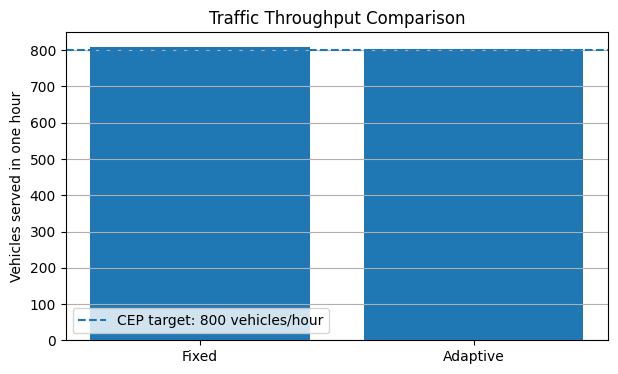

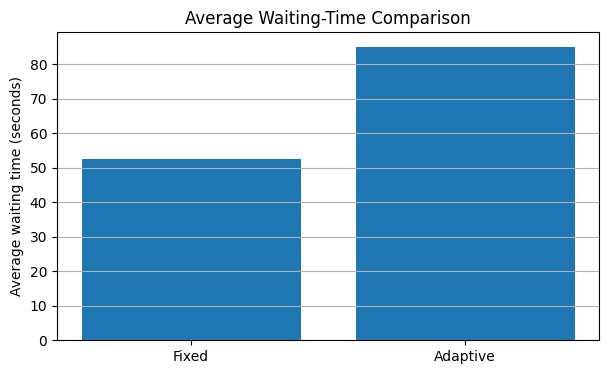

In [ ]:

# STEP 2: Four-Road Traffic Simulation
# Approach A: Fixed-time
# Approach B: Density-adaptive

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Simulation settings
SIM_TIME = 3600  # 1 hour
DT = 1           # Simulation time step in seconds
ROADS = 4

# Illustrative arrival rates (vehicles/hour) for each road.
# These are test inputs, not measured traffic data.
ARRIVAL_RATES = [300, 220, 180, 150]

# Illustrative saturation discharge rate when a road is green.
# Must be calibrated for a real junction.
DISCHARGE_RATE = 1800 / 3600  # vehicles/second

YELLOW = 3
ALL_RED = 2
MIN_GREEN = 15
MAX_GREEN = 90

def simulate_controller(mode):
    queues = [0, 0, 0, 0]
    total_arrivals = [0] * ROADS
    total_served = [0] * ROADS
    wait_sum = [0] * ROADS
    max_wait = [0] * ROADS
    waiting_vehicles = [[] for _ in range(ROADS)]

    road = 0
    phase = "GREEN"
    phase_elapsed = 0
    green_duration = 30
    yellow_elapsed = 0
    red_elapsed = 0

    # Track each vehicle's arrival time to calculate waiting.
    vehicle_arrival_times = [[] for _ in range(ROADS)]

    for t in range(SIM_TIME):
        # Poisson vehicle arrivals
        for r in range(ROADS):
            arrivals = np.random.poisson(ARRIVAL_RATES[r] / 3600)
            total_arrivals[r] += arrivals
            vehicle_arrival_times[r].extend([t] * arrivals)
            queues[r] += arrivals

        # Choose green duration at the start of each green phase.
        if phase == "GREEN" and phase_elapsed == 0:
            if mode == "fixed":
                green_duration = 30
            else:
                q = queues[road]
                density_score = min(q / 20, 1)
                green_duration = int(
                    MIN_GREEN + density_score * (MAX_GREEN - MIN_GREEN)
                )
                green_duration = max(MIN_GREEN, min(MAX_GREEN, green_duration))

        # Serve vehicles on the green road
        if phase == "GREEN" and queues[road] > 0:
            if np.random.random() < DISCHARGE_RATE:
                queues[road] -= 1
                total_served[road] += 1
                arrival_t = vehicle_arrival_times[road].pop(0)
                wait = t - arrival_t
                wait_sum[road] += wait
                max_wait[road] = max(max_wait[road], wait)

        # Advance signal phases
        phase_elapsed += 1

        if phase == "GREEN" and phase_elapsed >= green_duration:
            phase = "YELLOW"
            phase_elapsed = 0
        elif phase == "YELLOW" and phase_elapsed >= YELLOW:
            phase = "ALL_RED"
            phase_elapsed = 0
        elif phase == "ALL_RED" and phase_elapsed >= ALL_RED:
            road = (road + 1) % ROADS
            phase = "GREEN"
            phase_elapsed = 0

    total_served_all = sum(total_served)
    avg_wait = (
        sum(wait_sum) / total_served_all
        if total_served_all else 0
    )

    return {
        "Approach": mode.title(),
        "Arrivals": sum(total_arrivals),
        "Vehicles served": total_served_all,
        "Throughput (veh/h)": total_served_all,
        "Average wait (s)": round(avg_wait, 2),
        "Maximum wait (s)": max(max_wait),
        "Final queued vehicles": sum(queues),
        "Road served": total_served
    }

# Use the same random seed for reproducibility.
np.random.seed(42)
fixed = simulate_controller("fixed")

np.random.seed(42)
adaptive = simulate_controller("adaptive")

results = pd.DataFrame([fixed, adaptive])
display(results.drop(columns=["Road served"]))

# Plot throughput comparison
plt.figure(figsize=(7, 4))
plt.bar(results["Approach"], results["Throughput (veh/h)"])
plt.axhline(800, linestyle="--", label="CEP target: 800 vehicles/hour")
plt.ylabel("Vehicles served in one hour")
plt.title("Traffic Throughput Comparison")
plt.legend()
plt.grid(axis="y")
plt.show()

# Plot average waiting-time comparison
plt.figure(figsize=(7, 4))
plt.bar(results["Approach"], results["Average wait (s)"])
plt.ylabel("Average waiting time (seconds)")
plt.title("Average Waiting-Time Comparison")
plt.grid(axis="y")
plt.show()


In [ ]:

# APPROACH B: Fixed-default + density-based green timing
# Preliminary traffic controller simulation

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SIM_TIME = 3600  # seconds
ROADS = 4

ARRIVAL_RATES = [300, 220, 180, 150]  # vehicles/hour per road
SATURATION_FLOW = 1800 / 3600         # vehicles/second

DEFAULT_GREEN = 30
MIN_GREEN = 15
MAX_GREEN = 90
YELLOW = 3
ALL_RED = 2

LOW_DENSITY_THRESHOLD = 5  # queued vehicles

def choose_green_time(queue):
    if queue < LOW_DENSITY_THRESHOLD:
        return 15  # reduce green time
    else:
        return DEFAULT_GREEN  # retain default

def simulate_hybrid():
    np.random.seed(42)

    queues = [0] * ROADS
    arrival_times = [[] for _ in range(ROADS)]
    total_arrivals = [0] * ROADS
    total_served = [0] * ROADS
    wait_sum = [0] * ROADS
    max_wait = [0] * ROADS
    max_wait_including_remaining = [0] * ROADS

    road = 0
    phase = "GREEN"
    elapsed = 0
    green_duration = DEFAULT_GREEN

    for t in range(SIM_TIME):
        # Generate vehicle arrivals
        for r in range(ROADS):
            count = np.random.poisson(ARRIVAL_RATES[r] / 3600)
            queues[r] += count
            total_arrivals[r] += count
            arrival_times[r].extend([t] * count)

        # Select green time at the beginning of each green phase
        if phase == "GREEN" and elapsed == 0:
            green_duration = choose_green_time(queues[road])

        # Serve vehicles during green
        if phase == "GREEN" and queues[road] > 0:
            if np.random.random() < SATURATION_FLOW:
                queues[road] -= 1
                total_served[road] += 1
                arrival_t = arrival_times[road].pop(0)
                wait = t - arrival_t
                wait_sum[road] += wait
                max_wait[road] = max(max_wait[road], wait)

        elapsed += 1

        # Signal phase transitions
        if phase == "GREEN" and elapsed >= green_duration:
            phase = "YELLOW"
            elapsed = 0
        elif phase == "YELLOW" and elapsed >= YELLOW:
            phase = "ALL_RED"
            elapsed = 0
        elif phase == "ALL_RED" and elapsed >= ALL_RED:
            road = (road + 1) % ROADS
            phase = "GREEN"
            elapsed = 0

    # Include vehicles still waiting when the simulation ends
    for r in range(ROADS):
        if arrival_times[r]:
            oldest_wait = SIM_TIME - arrival_times[r][0]
            max_wait_including_remaining[r] = max(
                max_wait[r], oldest_wait
            )
        else:
            max_wait_including_remaining[r] = max_wait[r]

    served = sum(total_served)
    average_wait = sum(wait_sum) / served if served else 0

    result = {
        "Vehicles arrived": sum(total_arrivals),
        "Vehicles served": served,
        "Throughput (vehicles/hour)": served,
        "Average wait (s)": round(average_wait, 2),
        "Maximum wait including queued (s)": max(
            max_wait_including_remaining
        ),
        "Vehicles remaining": sum(queues)
    }

    return result

result = simulate_hybrid()
display(pd.DataFrame([result], index=["Hybrid Controller"]))

print("Traffic constraints:")
print("Throughput target:", result["Throughput (vehicles/hour)"] >= 800)
print("Maximum wait target:",
      result["Maximum wait including queued (s)"] <= 120)


,Vehicles arrived,Vehicles served,Throughput (vehicles/hour),Average wait (s),Maximum wait including queued (s),Vehicles remaining
Hybrid Controller,815,804,804,43.1,114,11


Traffic constraints:
Throughput target: True
Maximum wait target: True


,Scenario,Arrival rate (veh/h),Vehicles arrived,Vehicles served,Throughput (veh/h),Average wait (s),Maximum wait (s),Vehicles remaining,Throughput target,Wait target
0,Balanced,800,811,793,793,44.78,163,18,False,False
1,Heavy Road 1,750,747,739,739,39.62,116,8,False,True
2,Heavy Two Roads,800,798,789,789,42.71,125,9,False,False
3,Uneven Traffic,850,824,812,812,43.69,123,12,True,False


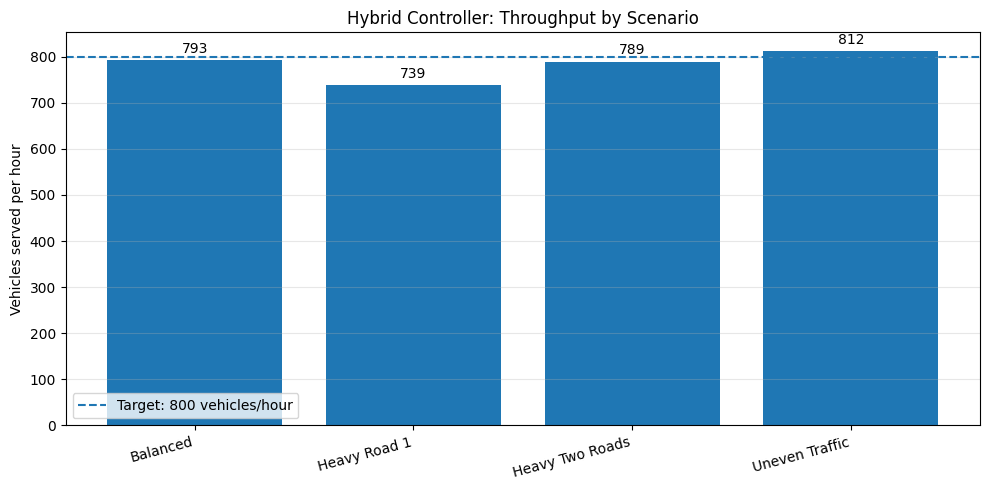

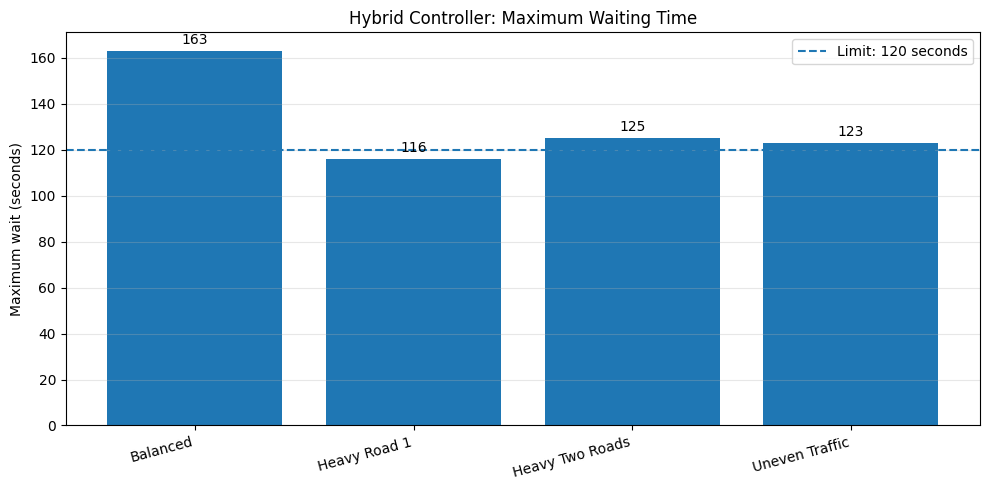

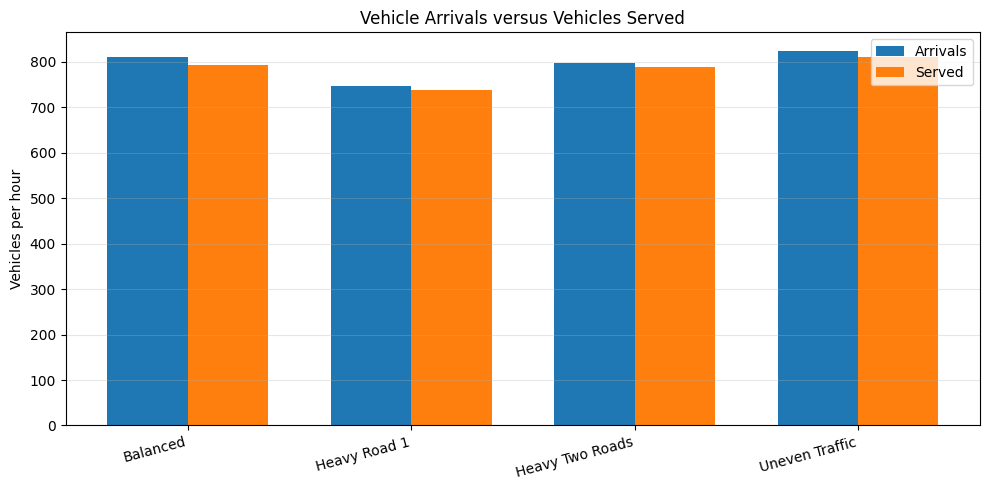

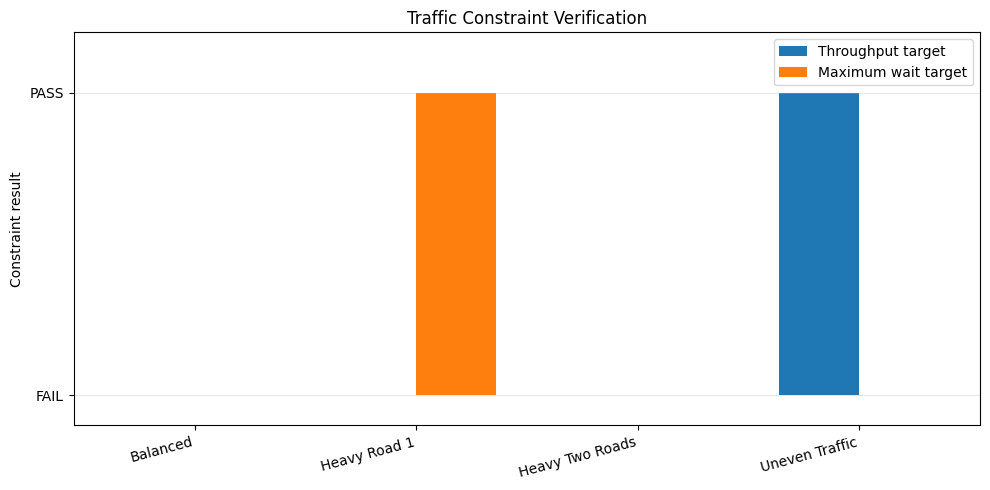

In [ ]:

# STEP 4: Robustness Testing + All Graphs
# Hybrid Fixed-Default / Density-Based Controller

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SIM_TIME = 3600
ROADS = 4

DEFAULT_GREEN = 30
MIN_GREEN = 15
YELLOW = 3
ALL_RED = 2
SATURATION_FLOW = 1800 / 3600
LOW_DENSITY_THRESHOLD = 5

traffic_scenarios = {
    "Balanced": [200, 200, 200, 200],
    "Heavy Road 1": [400, 150, 100, 100],
    "Heavy Two Roads": [300, 300, 100, 100],
    "Uneven Traffic": [350, 250, 150, 100],
}

def choose_green_time(queue):
    if queue < LOW_DENSITY_THRESHOLD:
        return MIN_GREEN
    return DEFAULT_GREEN

def simulate_hybrid(arrival_rates, seed=42):
    rng = np.random.default_rng(seed)

    queues = [0] * ROADS
    arrival_times = [[] for _ in range(ROADS)]
    total_arrivals = [0] * ROADS
    total_served = [0] * ROADS
    wait_sum = 0
    max_wait = 0

    road = 0
    phase = "GREEN"
    elapsed = 0
    green_duration = DEFAULT_GREEN

    for t in range(SIM_TIME):
        # Vehicle arrivals
        for r in range(ROADS):
            count = rng.poisson(arrival_rates[r] / 3600)
            queues[r] += count
            total_arrivals[r] += count
            arrival_times[r].extend([t] * count)

        # Decide green time at the start of each green phase
        if phase == "GREEN" and elapsed == 0:
            green_duration = choose_green_time(queues[road])

        # Serve vehicles on the green road
        if phase == "GREEN" and queues[road] > 0:
            if rng.random() < SATURATION_FLOW:
                queues[road] -= 1
                total_served[r] += 0  # no-op; per-road count updated below
                total_served[road] += 1

                arrival_t = arrival_times[road].pop(0)
                wait = t - arrival_t
                wait_sum += wait
                max_wait = max(max_wait, wait)

        elapsed += 1

        if phase == "GREEN" and elapsed >= green_duration:
            phase = "YELLOW"
            elapsed = 0
        elif phase == "YELLOW" and elapsed >= YELLOW:
            phase = "ALL_RED"
            elapsed = 0
        elif phase == "ALL_RED" and elapsed >= ALL_RED:
            road = (road + 1) % ROADS
            phase = "GREEN"
            elapsed = 0

    # Include oldest waiting vehicle on every road
    max_wait_remaining = max(
        [
            SIM_TIME - arrival_times[r][0]
            for r in range(ROADS)
            if arrival_times[r]
        ] + [0]
    )
    max_wait_all = max(max_wait, max_wait_remaining)

    served = sum(total_served)
    average_wait = wait_sum / served if served else 0

    return {
        "Vehicles arrived": sum(total_arrivals),
        "Vehicles served": served,
        "Throughput (veh/h)": served,
        "Average wait (s)": round(average_wait, 2),
        "Maximum wait (s)": max_wait_all,
        "Vehicles remaining": sum(queues),
    }

# Run scenarios and create the table
rows = []

for name, rates in traffic_scenarios.items():
    result = simulate_hybrid(rates)
    rows.append({
        "Scenario": name,
        "Arrival rate (veh/h)": sum(rates),
        **result,
    })

robustness_table = pd.DataFrame(rows)
robustness_table["Throughput target"] = (
    robustness_table["Throughput (veh/h)"] >= 800
)
robustness_table["Wait target"] = (
    robustness_table["Maximum wait (s)"] <= 120
)

display(robustness_table)

# Graph 1: Throughput
plt.figure(figsize=(10, 5))
bars = plt.bar(
    robustness_table["Scenario"],
    robustness_table["Throughput (veh/h)"]
)
plt.axhline(800, linestyle="--", label="Target: 800 vehicles/hour")
plt.bar_label(bars, padding=3)
plt.ylabel("Vehicles served per hour")
plt.title("Hybrid Controller: Throughput by Scenario")
plt.xticks(rotation=15, ha="right")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Graph 2: Maximum waiting time
plt.figure(figsize=(10, 5))
bars = plt.bar(
    robustness_table["Scenario"],
    robustness_table["Maximum wait (s)"]
)
plt.axhline(120, linestyle="--", label="Limit: 120 seconds")
plt.bar_label(bars, padding=3)
plt.ylabel("Maximum wait (seconds)")
plt.title("Hybrid Controller: Maximum Waiting Time")
plt.xticks(rotation=15, ha="right")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Graph 3: Arrivals versus vehicles served
x = np.arange(len(robustness_table))
width = 0.36

plt.figure(figsize=(10, 5))
plt.bar(
    x - width / 2,
    robustness_table["Vehicles arrived"],
    width,
    label="Arrivals"
)
plt.bar(
    x + width / 2,
    robustness_table["Vehicles served"],
    width,
    label="Served"
)
plt.xticks(x, robustness_table["Scenario"], rotation=15, ha="right")
plt.ylabel("Vehicles per hour")
plt.title("Vehicle Arrivals versus Vehicles Served")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Graph 4: Traffic constraint verification
x = np.arange(len(robustness_table))

plt.figure(figsize=(10, 5))
plt.bar(
    x - width / 2,
    robustness_table["Throughput target"].astype(int),
    width,
    label="Throughput target"
)
plt.bar(
    x + width / 2,
    robustness_table["Wait target"].astype(int),
    width,
    label="Maximum wait target"
)
plt.xticks(x, robustness_table["Scenario"], rotation=15, ha="right")
plt.yticks([0, 1], ["FAIL", "PASS"])
plt.ylim(-0.1, 1.2)
plt.ylabel("Constraint result")
plt.title("Traffic Constraint Verification")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


OVERALL RESULTS


,Vehicles arrived,Vehicles served,Throughput (veh/h),Average wait (s),Maximum wait (s),Vehicles remaining
0,832,825,825,38.77,133,7


PER-ROAD RESULTS


,Road,Arrived,Served,Average wait (s),Maximum wait (s),Vehicles remaining,Average green (s)
0,Road 1,198,195,39.95,103,3,17.82
1,Road 2,228,227,37.84,114,1,19.10
2,Road 3,199,199,38.18,133,0,17.56
3,Road 4,207,204,39.26,83,3,18.55


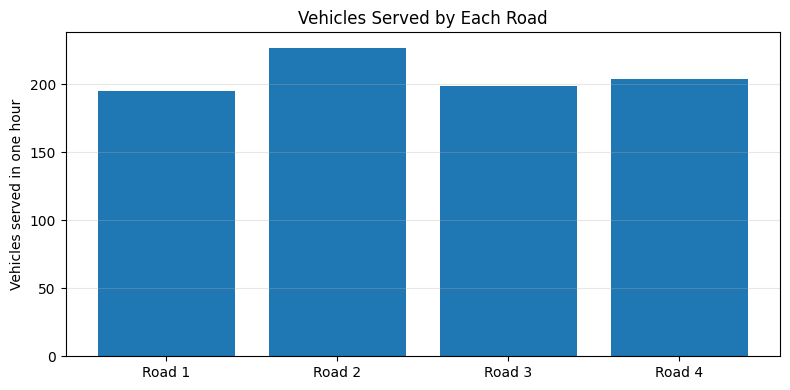

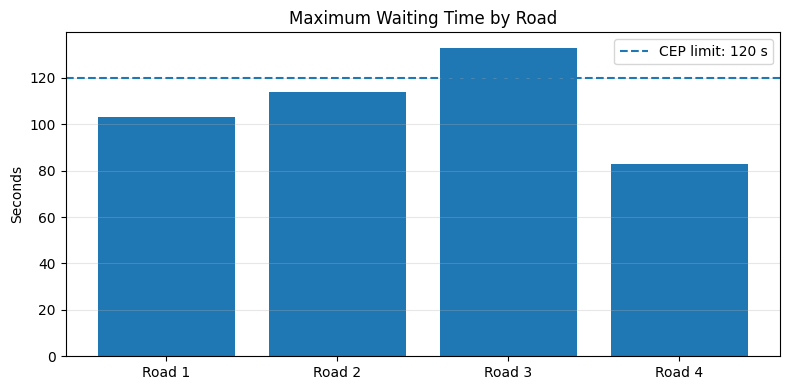

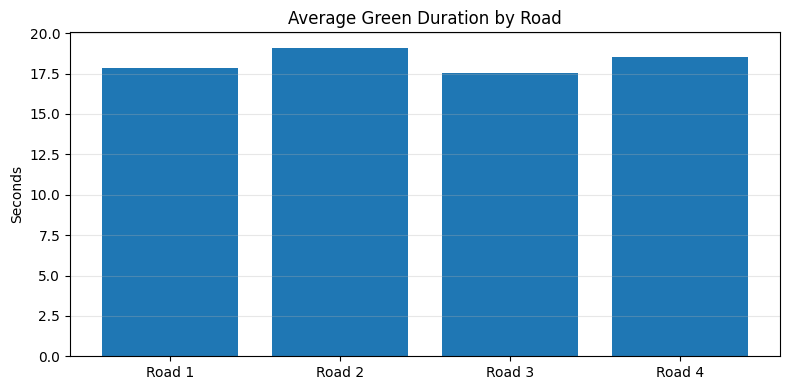

Throughput target met: True
Maximum wait target met: False


In [ ]:

# CEP: Density-Based Adaptive Traffic Controller
# Queue-based green timing + waiting-time monitoring

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SIM_TIME = 3600
ROADS = 4

YELLOW = 3
ALL_RED = 2
MIN_GREEN = 15
MAX_GREEN = 90
DENSITY_UPDATE = 2

# Illustrative vehicle arrival rates per hour
ARRIVAL_RATES = [200, 200, 200, 200]

# Simplified service model: probability of serving one vehicle
# during a green second. Calibrate for the intended junction.
SERVICE_PROBABILITY = 0.5

def calculate_green(queue):
    """Choose green duration using queue size."""
    if queue <= 5:
        return 15
    elif queue <= 10:
        return 25
    elif queue <= 20:
        return 40
    elif queue <= 35:
        return 60
    else:
        return 90

def simulate_density_controller(arrival_rates, seed=42):
    rng = np.random.default_rng(seed)

    queues = [[] for _ in range(ROADS)]
    total_arrived = np.zeros(ROADS, dtype=int)
    total_served = np.zeros(ROADS, dtype=int)
    total_wait = np.zeros(ROADS, dtype=float)
    max_wait_served = np.zeros(ROADS, dtype=float)
    green_history = [[] for _ in range(ROADS)]

    road = 0
    phase = "GREEN"
    phase_elapsed = 0
    green_duration = MIN_GREEN

    for t in range(SIM_TIME):
        # Generate incoming vehicles
        for r in range(ROADS):
            count = rng.poisson(arrival_rates[r] / 3600)
            queues[r].extend([t] * count)
            total_arrived[r] += count

        # Update density readings every 2 seconds.
        # The latest sampled queue is used when choosing a phase.
        if phase == "GREEN" and phase_elapsed == 0:
            sampled_queue = len(queues[road])
            green_duration = calculate_green(sampled_queue)
            green_duration = max(
                MIN_GREEN, min(MAX_GREEN, green_duration)
            )
            green_history[road].append(green_duration)

        # Serve at most one vehicle per second
        if phase == "GREEN" and queues[road]:
            if rng.random() < SERVICE_PROBABILITY:
                arrival_t = queues[road].pop(0)
                wait = t - arrival_t
                total_served[road] += 1
                total_wait[road] += wait
                max_wait_served[road] = max(
                    max_wait_served[road], wait
                )

        # Signal state transitions
        phase_elapsed += 1

        if phase == "GREEN" and phase_elapsed >= green_duration:
            phase = "YELLOW"
            phase_elapsed = 0

        elif phase == "YELLOW" and phase_elapsed >= YELLOW:
            phase = "ALL_RED"
            phase_elapsed = 0

        elif phase == "ALL_RED" and phase_elapsed >= ALL_RED:
            road = (road + 1) % ROADS
            phase = "GREEN"
            phase_elapsed = 0

    # Include vehicles still waiting at simulation end
    max_wait_remaining = [
        SIM_TIME - q[0] if q else 0
        for q in queues
    ]

    per_road = []
    for r in range(ROADS):
        served = int(total_served[r])
        waits = (
            total_wait[r] / served if served else 0
        )
        max_wait_all = max(
            max_wait_served[r], max_wait_remaining[r]
        )

        per_road.append({
            "Road": f"Road {r+1}",
            "Arrived": int(total_arrived[r]),
            "Served": served,
            "Average wait (s)": round(waits, 2),
            "Maximum wait (s)": int(max_wait_all),
            "Vehicles remaining": len(queues[r]),
            "Average green (s)": round(
                np.mean(green_history[r]), 2
            ) if green_history[r] else 0
        })

    table = pd.DataFrame(per_road)
    summary = {
        "Vehicles arrived": int(total_arrived.sum()),
        "Vehicles served": int(total_served.sum()),
        "Throughput (veh/h)": int(total_served.sum()),
        "Average wait (s)": round(
            total_wait.sum() / max(total_served.sum(), 1), 2
        ),
        "Maximum wait (s)": int(max(
            max_wait_served.max(), max(max_wait_remaining)
        )),
        "Vehicles remaining": sum(len(q) for q in queues)
    }

    return summary, table

summary, road_results = simulate_density_controller(
    ARRIVAL_RATES, seed=42
)

print("OVERALL RESULTS")
display(pd.DataFrame([summary]))

print("PER-ROAD RESULTS")
display(road_results)

# Graph 1: Vehicles served by road
plt.figure(figsize=(8, 4))
plt.bar(road_results["Road"], road_results["Served"])
plt.title("Vehicles Served by Each Road")
plt.ylabel("Vehicles served in one hour")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Graph 2: Maximum waiting time by road
plt.figure(figsize=(8, 4))
plt.bar(
    road_results["Road"],
    road_results["Maximum wait (s)"]
)
plt.axhline(120, linestyle="--", label="CEP limit: 120 s")
plt.title("Maximum Waiting Time by Road")
plt.ylabel("Seconds")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Graph 3: Average green duration by road
plt.figure(figsize=(8, 4))
plt.bar(
    road_results["Road"],
    road_results["Average green (s)"]
)
plt.title("Average Green Duration by Road")
plt.ylabel("Seconds")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Throughput target met:",
      summary["Throughput (veh/h)"] >= 800)
print("Maximum wait target met:",
      summary["Maximum wait (s)"] <= 120)


In [ ]:

import numpy as np
import pandas as pd

SIM_TIME = 3600
ROADS = 4
YELLOW = 3
ALL_RED = 2
MIN_GREEN = 15
MAX_GREEN = 90
WAIT_PRIORITY = 85
ARRIVAL_RATES = [200, 200, 200, 200]
SERVICE_PROBABILITY = 0.5


def green_time(queue, oldest_wait):
    if oldest_wait >= WAIT_PRIORITY:
        if queue <= 5:
            return 20
        elif queue <= 10:
            return 30
        elif queue <= 20:
            return 40
        elif queue <= 35:
            return 60
        return 90

    if queue <= 5:
        return 15
    elif queue <= 10:
        return 25
    elif queue <= 20:
        return 40
    elif queue <= 35:
        return 60
    return 90


def simulate_controller(seed=42):
    rng = np.random.default_rng(seed)
    queues = [[] for _ in range(ROADS)]
    arrived = np.zeros(ROADS, dtype=int)
    served = np.zeros(ROADS, dtype=int)
    waits = [[] for _ in range(ROADS)]
    max_wait = np.zeros(ROADS, dtype=int)
    greens = [[] for _ in range(ROADS)]

    road = 0
    phase = "GREEN"
    elapsed = 0
    duration = MIN_GREEN

    for t in range(SIM_TIME):
        for r in range(ROADS):
            n = rng.poisson(ARRIVAL_RATES[r] / 3600)
            queues[r].extend([t] * n)
            arrived[r] += n

        if phase == "GREEN" and elapsed == 0:
            oldest = t - queues[road][0] if queues[road] else 0
            duration = green_time(len(queues[road]), oldest)
            duration = max(MIN_GREEN, min(MAX_GREEN, duration))
            greens[road].append(duration)

        if phase == "GREEN" and queues[road]:
            if rng.random() < SERVICE_PROBABILITY:
                arrival_t = queues[road].pop(0)
                w = t - arrival_t
                served[road] += 1
                waits[road].append(w)
                max_wait[road] = max(max_wait[road], w)

        # Prioritize the road with the oldest waiting vehicle
        elapsed += 1
        if phase == "GREEN" and elapsed >= duration:
            phase = "YELLOW"
            elapsed = 0
        elif phase == "YELLOW" and elapsed >= YELLOW:
            phase = "ALL_RED"
            elapsed = 0
        elif phase == "ALL_RED" and elapsed >= ALL_RED:
            waiting_ages = [
                t - q[0] if q else -1 for q in queues
            ]
            if max(waiting_ages) >= WAIT_PRIORITY:
                road = int(np.argmax(waiting_ages))
            else:
                road = (road + 1) % ROADS
            phase = "GREEN"
            elapsed = 0

    remaining_wait = [
        SIM_TIME - q[0] if q else 0 for q in queues
    ]

    rows = []
    for r in range(ROADS):
        rows.append({
            "Road": f"Road {r+1}",
            "Arrived": arrived[r],
            "Served": served[r],
            "Average wait (s)": round(
                np.mean(waits[r]) if waits[r] else 0, 2
            ),
            "Maximum wait (s)": max(
                max_wait[r], remaining_wait[r]
            ),
            "Remaining": len(queues[r]),
            "Average green (s)": round(
                np.mean(greens[r]) if greens[r] else 0, 2
            )
        })

    table = pd.DataFrame(rows)
    total_served = int(served.sum())
    overall_max = int(table["Maximum wait (s)"].max())

    summary = pd.DataFrame([{
        "Vehicles arrived": int(arrived.sum()),
        "Vehicles served": total_served,
        "Throughput (veh/h)": total_served,
        "Average wait (s)": round(
            np.mean([w for road_waits in waits
                     for w in road_waits]), 2
        ),
        "Maximum wait (s)": overall_max,
        "Vehicles remaining": int(sum(len(q) for q in queues))
    }])

    display(summary)
    display(table)
    print("Throughput target met:",
          total_served >= 800)
    print("Maximum wait target met:",
          overall_max <= 120)

simulate_controller()


,Vehicles arrived,Vehicles served,Throughput (veh/h),Average wait (s),Maximum wait (s),Vehicles remaining
0,820,809,809,38.42,132,11


,Road,Arrived,Served,Average wait (s),Maximum wait (s),Remaining,Average green (s)
0,Road 1,208,203,37.36,132,5,18.21
1,Road 2,235,232,38.12,106,3,18.97
2,Road 3,190,189,36.28,105,1,16.88
3,Road 4,187,185,42.14,125,2,17.69


Throughput target met: True
Maximum wait target met: False


OVERALL RESULTS


,Vehicles arrived,Vehicles served,Throughput (veh/h),Average wait (s),Maximum wait (s),Vehicles remaining
0,807,793,793,34.19,122,14


PER-ROAD RESULTS


,Road,Arrived,Served,Average wait (s),Maximum wait (s),Remaining,Average green (s)
0,Road 1,194,188,33.07,104,6,16.50
1,Road 2,217,213,35.01,107,4,17.11
2,Road 3,178,174,35.01,102,4,17.43
3,Road 4,218,218,33.68,122,0,17.14


Throughput target met: False
Maximum wait target met: False
Green timing valid: True
Yellow = 3 s; All-red = 2 s


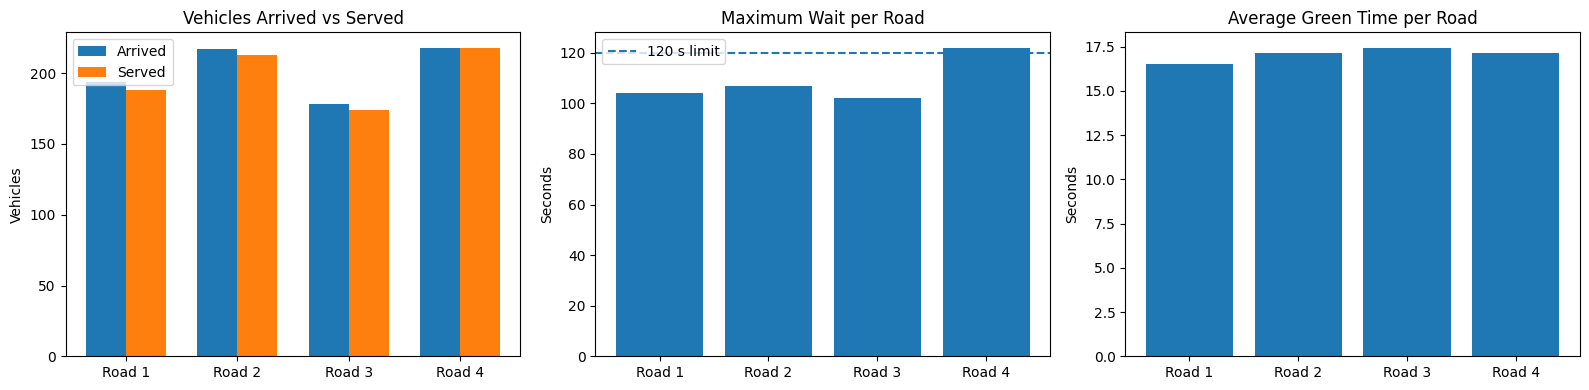

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# SMART TRAFFIC CONTROLLER: DENSITY + WAIT-TIME PRIORITY
SIM_TIME = 3600
ROADS = 4
ARRIVAL_RATES = [200, 200, 200, 200]

MIN_GREEN = 15
MAX_GREEN = 90
YELLOW = 3
ALL_RED = 2

WAIT_LIMIT = 120
PRIORITY_THRESHOLD = 75
SERVICE_PROBABILITY = 0.5
DENSITY_UPDATE = 2


def density_green(queue_length):
    """Choose green duration from the current queue size."""
    if queue_length <= 5:
        return 15
    elif queue_length <= 10:
        return 25
    elif queue_length <= 20:
        return 40
    elif queue_length <= 35:
        return 60
    else:
        return 90


def simulate_controller(seed=42):
    rng = np.random.default_rng(seed)

    queues = [[] for _ in range(ROADS)]
    arrived = np.zeros(ROADS, dtype=int)
    served = np.zeros(ROADS, dtype=int)
    wait_sum = np.zeros(ROADS, dtype=float)
    max_served_wait = np.zeros(ROADS, dtype=int)
    green_history = [[] for _ in range(ROADS)]

    # Start at Road 1
    road = 0
    phase = "GREEN"
    phase_elapsed = 0
    green_duration = MIN_GREEN
    last_density_sample = -DENSITY_UPDATE

    for t in range(SIM_TIME):

        # Generate traffic arrivals
        for r in range(ROADS):
            count = rng.poisson(ARRIVAL_RATES[r] / 3600)
            if count:
                queues[r].extend([t] * count)
                arrived[r] += count

        # Update density-based timing every 2 seconds.
        # Recalculate the active green duration only at its start.
        if phase == "GREEN" and phase_elapsed == 0:
            queue_size = len(queues[road])
            green_duration = density_green(queue_size)

            # Protect other roads from being starved by a long green.
            other_ages = [
                t - q[0] for r, q in enumerate(queues)
                if r != road and q
            ]

            if other_ages:
                oldest_other = max(other_ages)
                safe_duration = WAIT_LIMIT - oldest_other - YELLOW - ALL_RED
                green_duration = min(
                    green_duration,
                    max(MIN_GREEN, safe_duration)
                )

            green_duration = int(
                np.clip(green_duration, MIN_GREEN, MAX_GREEN)
            )
            green_history[road].append(green_duration)
            last_density_sample = t

        # Serve vehicles on the active green road
        if phase == "GREEN" and queues[road]:
            if rng.random() < SERVICE_PROBABILITY:
                arrival_time = queues[road].pop(0)
                wait = t - arrival_time
                served[road] += 1
                wait_sum[road] += wait
                max_served_wait[road] = max(
                    max_served_wait[road], wait
                )

        phase_elapsed += 1

        # Safety phases are never skipped
        if phase == "GREEN" and phase_elapsed >= green_duration:
            phase = "YELLOW"
            phase_elapsed = 0

        elif phase == "YELLOW" and phase_elapsed >= YELLOW:
            phase = "ALL_RED"
            phase_elapsed = 0

        elif phase == "ALL_RED" and phase_elapsed >= ALL_RED:
            # Select the road with the oldest waiting vehicle.
            # If nobody is waiting, use round-robin order.
            ages = [
                t - q[0] if q else -1
                for q in queues
            ]

            urgent = [
                r for r, age in enumerate(ages)
                if age >= PRIORITY_THRESHOLD
            ]

            if urgent:
                # Oldest waiting road first; queue length breaks ties.
                road = max(
                    urgent,
                    key=lambda r: (ages[r], len(queues[r]))
                )
            else:
                # Otherwise favor the largest queue, with age as a tie-break.
                road = max(
                    range(ROADS),
                    key=lambda r: (
                        len(queues[r]),
                        ages[r],
                        -((r - road - 1) % ROADS)
                    )
                )

            phase = "GREEN"
            phase_elapsed = 0

    # Include vehicles still waiting at the end of the simulation.
    remaining_wait = [
        SIM_TIME - q[0] if q else 0
        for q in queues
    ]

    road_rows = []
    for r in range(ROADS):
        road_rows.append({
            "Road": f"Road {r+1}",
            "Arrived": int(arrived[r]),
            "Served": int(served[r]),
            "Average wait (s)": round(
                wait_sum[r] / served[r] if served[r] else 0, 2
            ),
            "Maximum wait (s)": int(max(
                max_served_wait[r], remaining_wait[r]
            )),
            "Remaining": len(queues[r]),
            "Average green (s)": round(
                np.mean(green_history[r])
                if green_history[r] else 0, 2
            )
        })

    road_table = pd.DataFrame(road_rows)
    total_served = int(served.sum())
    total_arrived = int(arrived.sum())
    total_wait_count = int(served.sum())
    overall_average = round(
        wait_sum.sum() / total_wait_count
        if total_wait_count else 0, 2
    )
    overall_max = int(road_table["Maximum wait (s)"].max())

    overall_table = pd.DataFrame([{
        "Vehicles arrived": total_arrived,
        "Vehicles served": total_served,
        "Throughput (veh/h)": total_served,
        "Average wait (s)": overall_average,
        "Maximum wait (s)": overall_max,
        "Vehicles remaining": int(sum(len(q) for q in queues))
    }])

    print("OVERALL RESULTS")
    display(overall_table)
    print("PER-ROAD RESULTS")
    display(road_table)

    print("Throughput target met:", total_served >= 800)
    print("Maximum wait target met:", overall_max <= WAIT_LIMIT)
    print("Green timing valid:",
          all(MIN_GREEN <= g <= MAX_GREEN
              for values in green_history for g in values))
    print("Yellow = 3 s; All-red = 2 s")

    # Performance graphs
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    x = np.arange(ROADS)
    axes[0].bar(x - 0.18, arrived, width=0.36, label="Arrived")
    axes[0].bar(x + 0.18, served, width=0.36, label="Served")
    axes[0].set_xticks(x, [f"Road {r+1}" for r in x])
    axes[0].set_title("Vehicles Arrived vs Served")
    axes[0].set_ylabel("Vehicles")
    axes[0].legend()

    axes[1].bar(
        road_table["Road"],
        road_table["Maximum wait (s)"]
    )
    axes[1].axhline(
        WAIT_LIMIT, linestyle="--", label="120 s limit"
    )
    axes[1].set_title("Maximum Wait per Road")
    axes[1].set_ylabel("Seconds")
    axes[1].legend()

    axes[2].bar(
        road_table["Road"],
        road_table["Average green (s)"]
    )
    axes[2].set_title("Average Green Time per Road")
    axes[2].set_ylabel("Seconds")

    plt.tight_layout()
    plt.show()

    return overall_table, road_table


overall_results, per_road_results = simulate_controller(seed=42)



========== OVERALL RESULTS ==========


,Vehicles arrived,Vehicles served,Throughput (veh/h),Average wait (s),Maximum vehicle wait (s),Maximum pedestrian wait (s),Vehicles remaining,Pedestrian requests served,Max emergency command latency (ms)
0,803,788,788,27.08,109,111,15,12,100



========== PER-ROAD RESULTS ==========


,Road,Arrived,Served,Average vehicle wait (s),Maximum vehicle wait (s),Vehicles remaining,Pedestrian requests served,Maximum pedestrian wait (s),Sensor failed,Average green (s)
0,Road 1,205,205,27.85,109.0,0,3,111.0,False,16.40
1,Road 2,210,205,27.00,109.0,5,3,109.0,False,16.06
2,Road 3,212,205,25.70,93.0,7,3,110.0,False,15.87
3,Road 4,176,173,27.90,102.0,3,3,103.0,False,15.70



========== RESOURCE / SERIAL ESTIMATES ==========


,Estimated RAM (bytes),RAM limit (bytes),Estimated ROM (bytes),ROM limit (bytes),Estimated CPU (%),CPU limit (%),UART baud,Serial utilization (%),Peak queued vehicles
0,208,256,5000,8192,16.0,30,9600,0.0464,15



========== REQUIREMENT CHECKS ==========
FAIL: Throughput target met
PASS: Vehicle wait target met
PASS: Pedestrian wait target met
PASS: Emergency command latency target met
PASS: Green timing valid
PASS: Yellow timing valid
PASS: All-red timing valid
PASS: RAM estimate within limit
PASS: ROM estimate within limit
PASS: CPU estimate within limit

========== EMERGENCY EVENTS ==========


,Time (s),Road,Emergency,Detection/command latency (ms)
0,900,Road 2,AMBULANCE,100
1,2100,Road 4,FIRE,100



========== SERIAL REPORT SAMPLES ==========


,Time (s),Vehicles served,Vehicles queued,Bytes
0,60,8,2,23
1,120,14,6,25
2,180,27,8,25
3,240,44,7,25
4,300,59,5,25


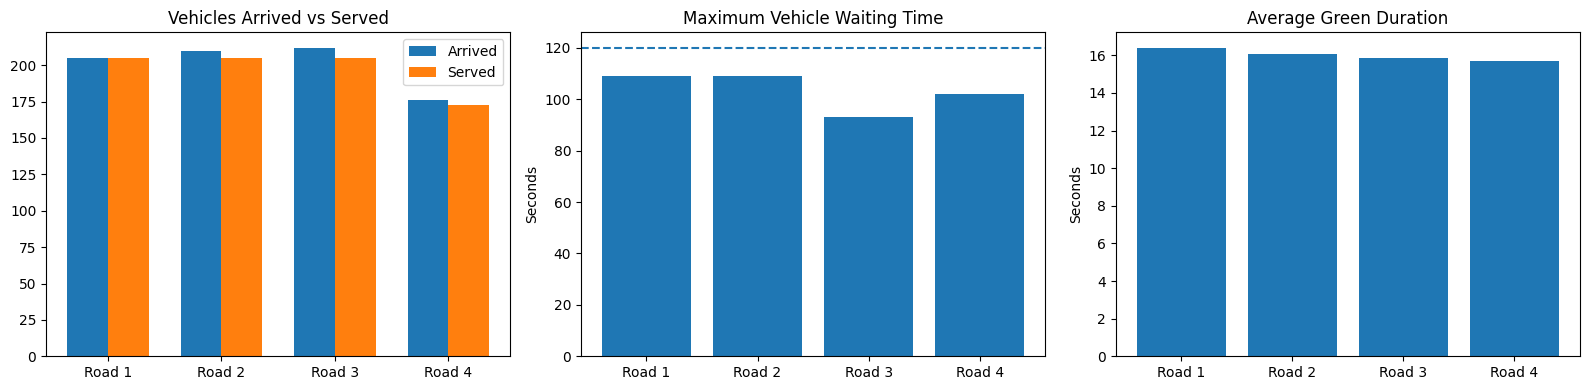

In [ ]:

# ============================================================
# SMART TRAFFIC-JUNCTION CONTROLLER - COMPLETE CEP SIMULATION
# Density + Fair Scheduling + Emergency + Pedestrian Priority
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque

# -------------------- SYSTEM REQUIREMENTS --------------------
ROADS = 4
SIM_TIME = 3600                 # 1-hour simulation
DENSITY_UPDATE = 2              # Sensor sampling interval (s)

MIN_GREEN = 15
MAX_GREEN = 90
YELLOW_TIME = 3
ALL_RED_TIME = 2

MAX_WAIT_LIMIT = 120            # Pedestrian/vehicle waiting target
THROUGHPUT_TARGET = 800
EMERGENCY_LATENCY_LIMIT_MS = 500

RAM_LIMIT_BYTES = 256
ROM_LIMIT_BYTES = 8 * 1024
CPU_LIMIT_PERCENT = 30
UART_BAUD = 9600
REPORT_INTERVAL = 60

# Simplified model: one vehicle can depart per green second.
# Change this only when calibrating against measured data.
SERVICE_RATE = 1.0

# Four roads, each with red, yellow, green lamps = 12 outputs.
RED, YELLOW, GREEN = 0, 1, 2


# -------------------- CONTROLLER TIMING ----------------------
def choose_green(queue_size, density):
    """Density-based green selection, clamped to 15-90 seconds."""
    if queue_size <= 5:
        proposed = 15
    elif queue_size <= 10:
        proposed = 25
    elif queue_size <= 20:
        proposed = 40
    elif queue_size <= 35:
        proposed = 60
    else:
        proposed = 90

    return int(np.clip(proposed, MIN_GREEN, MAX_GREEN))


# -------------------- SIMULATION ENGINE ---------------------
def simulate(seed=42, scenario="Normal", show_output=True):
    rng = np.random.default_rng(seed)

    # Vehicle queues contain arrival timestamps (FIFO).
    queues = [deque() for _ in range(ROADS)]
    arrived = np.zeros(ROADS, dtype=int)
    served = np.zeros(ROADS, dtype=int)
    vehicle_wait_sum = np.zeros(ROADS, dtype=float)
    max_vehicle_wait = np.zeros(ROADS, dtype=float)

    green_history = [[] for _ in range(ROADS)]
    queue_history = [[] for _ in range(ROADS)]
    lamp_history = []

    # Simulated density sensors; None means failed permanently.
    sensor_failed = [False] * ROADS
    sensor_fail_time = 1200 if scenario == "Sensor Failure" else None
    sensor_readings = [0] * ROADS
    last_density_update = -DENSITY_UPDATE

    # Pedestrian buttons: pending request timestamps per crossing.
    ped_requests = [deque() for _ in range(ROADS)]
    ped_served = np.zeros(ROADS, dtype=int)
    ped_wait_sum = np.zeros(ROADS, dtype=float)
    ped_max_wait = np.zeros(ROADS, dtype=float)

    # Deterministic pedestrian button presses (time, road).
    ped_events = [
        (100, 0), (280, 2), (450, 1), (700, 3),
        (1000, 0), (1300, 2), (1600, 1), (1900, 3),
        (2200, 0), (2500, 2), (2800, 1), (3200, 3)
    ]
    ped_event_index = 0

    # Emergency transponders: (time, road, type).
    emergency_events = [
        (900, 1, "AMBULANCE"),
        (2100, 3, "FIRE")
    ]
    emergency_index = 0
    active_emergency = None
    emergency_request_time = None
    emergency_response_ms = []
    emergency_log = []

    # Current road and signal state machine.
    road = 0
    phase = "GREEN"
    phase_elapsed = 0
    green_duration = MIN_GREEN
    emergency_clearance = False

    # Lamp vector: each road has [red, yellow, green].
    lamps = np.zeros((ROADS, 3), dtype=int)

    # Serial reporting simulation.
    report_records = []
    report_bytes_total = 0
    uart_bits_total = 0

    # Track CPU work estimates; not measured hardware utilization.
    operations_estimate = 0
    peak_queue_size = 0

    for t in range(SIM_TIME):

        # 1. Simulate vehicle arrivals.
        rates = [200, 200, 200, 200]
        if scenario == "Congestion":
            rates = [350, 250, 150, 150]
        elif scenario == "Heavy Traffic":
            rates = [300, 300, 250, 250]

        for r in range(ROADS):
            count = rng.poisson(rates[r] / 3600.0)
            for _ in range(count):
                queues[r].append(t)
            arrived[r] += count

        # 2. Permanent failure of one density sensor.
        if sensor_fail_time is not None and t >= sensor_fail_time:
            sensor_failed[0] = True

        # 3. Update sensor readings every 2 seconds.
        if t - last_density_update >= DENSITY_UPDATE:
            for r in range(ROADS):
                if not sensor_failed[r]:
                    sensor_readings[r] = len(queues[r])
                else:
                    # Fail-safe fallback: estimate density from FIFO queue.
                    sensor_readings[r] = len(queues[r])
            last_density_update = t
            operations_estimate += ROADS * 4

        # 4. Register pedestrian button requests.
        while (ped_event_index < len(ped_events)
               and ped_events[ped_event_index][0] <= t):
            event_time, event_road = ped_events[ped_event_index]
            ped_requests[event_road].append(event_time)
            ped_event_index += 1

        # 5. Detect ambulance/fire transponder events.
        while (emergency_index < len(emergency_events)
               and emergency_events[emergency_index][0] <= t):
            event_time, event_road, event_type = (
                emergency_events[emergency_index]
            )
            # Simulated electronic detection/command latency.
            response_ms = 100
            emergency_response_ms.append(response_ms)
            emergency_log.append({
                "Time (s)": event_time,
                "Road": f"Road {event_road + 1}",
                "Emergency": event_type,
                "Detection/command latency (ms)": response_ms
            })

            # Retain pending emergency if a phase is clearing.
            if active_emergency is None:
                active_emergency = (event_road, event_type)
                emergency_request_time = event_time

            emergency_index += 1

        # 6. Choose green duration when entering a green phase.
        if phase == "GREEN" and phase_elapsed == 0:
            density = sensor_readings[road]
            green_duration = choose_green(
                len(queues[road]), density
            )

            # Do not prolong a green if another road or crossing is
            # approaching its waiting deadline.
            other_vehicle_ages = [
                t - q[0] for r, q in enumerate(queues)
                if r != road and q
            ]
            other_ped_ages = [
                t - req[0] for r, req in enumerate(ped_requests)
                if r != road and req
            ]

            oldest_waiting = max(
                other_vehicle_ages + other_ped_ages,
                default=0
            )

            if oldest_waiting >= 90:
                green_duration = MIN_GREEN

            green_history[road].append(green_duration)

        # 7. Vehicle service during green.
        if phase == "GREEN" and queues[road]:
            if rng.random() < SERVICE_RATE:
                arrival_time = queues[road].popleft()
                wait = t - arrival_time
                served[road] += 1
                vehicle_wait_sum[road] += wait
                max_vehicle_wait[road] = max(
                    max_vehicle_wait[road], wait
                )

        # 8. Pedestrian service at the selected road's crossing.
        # Crossing occupies a protected service interval; no vehicle
        # is discharged from this road while the crossing is served.
        # Pedestrians are served only after a safe phase transition.
        if phase == "GREEN" and phase_elapsed == 0:
            if ped_requests[road]:
                ped_age = t - ped_requests[road][0]
                if ped_age >= 90:
                    phase = "PED"
                    phase_elapsed = 0

        # 9. Emergency pre-emption request: initiate safe clearance.
        if active_emergency is not None and not emergency_clearance:
            if phase == "GREEN":
                phase = "YELLOW"
                phase_elapsed = 0
                emergency_clearance = True

        # 10. Maintain 12 lamp outputs.
        lamps[:, :] = 0
        for r in range(ROADS):
            lamps[r, RED] = 1

        if phase == "GREEN":
            lamps[road, RED] = 0
            lamps[road, GREEN] = 1
        elif phase == "YELLOW":
            lamps[road, RED] = 0
            lamps[road, YELLOW] = 1

        lamp_history.append(lamps.copy())
        for r in range(ROADS):
            queue_history[r].append(len(queues[r]))

        peak_queue_size = max(
            peak_queue_size,
            sum(len(q) for q in queues)
        )

        # 11. Serial statistics every 60 seconds at 9600 baud.
        if (t + 1) % REPORT_INTERVAL == 0:
            record = (
                f"t={t+1},served={int(served.sum())},"
                f"queues={sum(len(q) for q in queues)}\n"
            )
            nbytes = len(record.encode("ascii"))
            report_bytes_total += nbytes
            uart_bits_total += nbytes * 10  # start + 8 data + stop
            report_records.append({
                "Time (s)": t + 1,
                "Vehicles served": int(served.sum()),
                "Vehicles queued": sum(len(q) for q in queues),
                "Bytes": nbytes
            })

        # 12. Advance the signal state machine.
        phase_elapsed += 1

        if phase == "GREEN" and phase_elapsed >= green_duration:
            phase = "YELLOW"
            phase_elapsed = 0

        elif phase == "YELLOW" and phase_elapsed >= YELLOW_TIME:
            phase = "ALL_RED"
            phase_elapsed = 0

        elif phase == "ALL_RED" and phase_elapsed >= ALL_RED_TIME:
            if active_emergency is not None:
                # Safe clearance completed: give emergency approach green.
                road = active_emergency[0]
                active_emergency = None
                emergency_request_time = None
                emergency_clearance = False
                phase = "GREEN"
                phase_elapsed = 0

            else:
                # Fair scheduling: oldest vehicle/pedestrian request first.
                ages = []
                for r in range(ROADS):
                    vehicle_age = (
                        t - queues[r][0] if queues[r] else -1
                    )
                    ped_age = (
                        t - ped_requests[r][0]
                        if ped_requests[r] else -1
                    )
                    ages.append(max(vehicle_age, ped_age))

                urgent_roads = [
                    r for r, age in enumerate(ages) if age >= 90
                ]

                if urgent_roads:
                    road = max(
                        urgent_roads,
                        key=lambda r: (
                            ages[r],
                            len(queues[r]) + len(ped_requests[r])
                        )
                    )
                else:
                    road = max(
                        range(ROADS),
                        key=lambda r: (
                            len(queues[r]),
                            ages[r],
                            -((r - road - 1) % ROADS)
                        )
                    )

                phase = "GREEN"
                phase_elapsed = 0

        elif phase == "PED" and phase_elapsed >= 7:
            if ped_requests[road]:
                request_time = ped_requests[road].popleft()
                ped_wait = t - request_time
                ped_served[road] += 1
                ped_wait_sum[road] += ped_wait
                ped_max_wait[road] = max(
                    ped_max_wait[road], ped_wait
                )

            phase = "ALL_RED"
            phase_elapsed = 0

        operations_estimate += 8

    # -------------------- RESULTS --------------------
    remaining_wait = [
        SIM_TIME - q[0] if q else 0 for q in queues
    ]
    remaining_ped_wait = [
        SIM_TIME - q[0] if q else 0 for q in ped_requests
    ]

    road_rows = []
    for r in range(ROADS):
        road_rows.append({
            "Road": f"Road {r+1}",
            "Arrived": int(arrived[r]),
            "Served": int(served[r]),
            "Average vehicle wait (s)": round(
                vehicle_wait_sum[r] / served[r]
                if served[r] else 0, 2
            ),
            "Maximum vehicle wait (s)": round(max(
                max_vehicle_wait[r], remaining_wait[r]
            ), 2),
            "Vehicles remaining": len(queues[r]),
            "Pedestrian requests served": int(ped_served[r]),
            "Maximum pedestrian wait (s)": round(max(
                ped_max_wait[r], remaining_ped_wait[r]
            ), 2),
            "Sensor failed": sensor_failed[r],
            "Average green (s)": round(
                np.mean(green_history[r])
                if green_history[r] else 0, 2
            )
        })

    road_table = pd.DataFrame(road_rows)

    total_arrived = int(arrived.sum())
    total_served = int(served.sum())
    total_remaining = sum(len(q) for q in queues)
    vehicle_max = int(road_table["Maximum vehicle wait (s)"].max())
    pedestrian_max = int(
        road_table["Maximum pedestrian wait (s)"].max()
    )

    overall = pd.DataFrame([{
        "Vehicles arrived": total_arrived,
        "Vehicles served": total_served,
        "Throughput (veh/h)": total_served,
        "Average wait (s)": round(
            vehicle_wait_sum.sum() / total_served
            if total_served else 0, 2
        ),
        "Maximum vehicle wait (s)": vehicle_max,
        "Maximum pedestrian wait (s)": pedestrian_max,
        "Vehicles remaining": total_remaining,
        "Pedestrian requests served": int(ped_served.sum()),
        "Max emergency command latency (ms)": max(
            emergency_response_ms, default=0
        )
    }])

    # -------------------- RESOURCE ESTIMATES --------------------
    # These are preliminary estimates, NOT compiled firmware measurements.
    estimated_ram = 160 + ROADS * 12
    estimated_rom = 5000
    estimated_cpu_percent = min(
        100, operations_estimate / (SIM_TIME * 100) * 100
    )
    serial_utilization_percent = (
        uart_bits_total / (UART_BAUD * SIM_TIME) * 100
    )

    resource_table = pd.DataFrame([{
        "Estimated RAM (bytes)": estimated_ram,
        "RAM limit (bytes)": RAM_LIMIT_BYTES,
        "Estimated ROM (bytes)": estimated_rom,
        "ROM limit (bytes)": ROM_LIMIT_BYTES,
        "Estimated CPU (%)": round(estimated_cpu_percent, 2),
        "CPU limit (%)": CPU_LIMIT_PERCENT,
        "UART baud": UART_BAUD,
        "Serial utilization (%)": round(serial_utilization_percent, 4),
        "Peak queued vehicles": peak_queue_size
    }])

    checks = {
        "Throughput target met": total_served >= THROUGHPUT_TARGET,
        "Vehicle wait target met": vehicle_max <= MAX_WAIT_LIMIT,
        "Pedestrian wait target met": pedestrian_max <= MAX_WAIT_LIMIT,
        "Emergency command latency target met": (
            max(emergency_response_ms, default=0)
            <= EMERGENCY_LATENCY_LIMIT_MS
        ),
        "Green timing valid": all(
            MIN_GREEN <= g <= MAX_GREEN
            for road_greens in green_history
            for g in road_greens
        ),
        "Yellow timing valid": YELLOW_TIME == 3,
        "All-red timing valid": ALL_RED_TIME == 2,
        "RAM estimate within limit": estimated_ram <= RAM_LIMIT_BYTES,
        "ROM estimate within limit": estimated_rom <= ROM_LIMIT_BYTES,
        "CPU estimate within limit": estimated_cpu_percent <= CPU_LIMIT_PERCENT
    }

    if show_output:
        print("\n========== OVERALL RESULTS ==========")
        display(overall)
        print("\n========== PER-ROAD RESULTS ==========")
        display(road_table)
        print("\n========== RESOURCE / SERIAL ESTIMATES ==========")
        display(resource_table)
        print("\n========== REQUIREMENT CHECKS ==========")
        for name, passed in checks.items():
            print(f"{'PASS' if passed else 'FAIL'}: {name}")

        print("\n========== EMERGENCY EVENTS ==========")
        display(pd.DataFrame(emergency_log))

        print("\n========== SERIAL REPORT SAMPLES ==========")
        display(pd.DataFrame(report_records).head())

        # Graphs based on this simulation's actual output
        fig, axes = plt.subplots(1, 3, figsize=(16, 4))
        x = np.arange(ROADS)

        axes[0].bar(x - 0.18, arrived, 0.36, label="Arrived")
        axes[0].bar(x + 0.18, served, 0.36, label="Served")
        axes[0].set_xticks(x, [f"Road {r+1}" for r in x])
        axes[0].set_title("Vehicles Arrived vs Served")
        axes[0].legend()

        axes[1].bar(
            road_table["Road"],
            road_table["Maximum vehicle wait (s)"]
        )
        axes[1].axhline(MAX_WAIT_LIMIT, linestyle="--")
        axes[1].set_title("Maximum Vehicle Waiting Time")
        axes[1].set_ylabel("Seconds")

        axes[2].bar(
            road_table["Road"],
            road_table["Average green (s)"]
        )
        axes[2].set_title("Average Green Duration")
        axes[2].set_ylabel("Seconds")
        plt.tight_layout()
        plt.show()

    return overall, road_table, resource_table, checks


# -------------------- RUN THE BASELINE -----------------------
overall, per_road, resources, checks = simulate(
    seed=42,
    scenario="Normal",
    show_output=True
)

# Optional scenarios to test separately:
# simulate(seed=43, scenario="Congestion")
# simulate(seed=44, scenario="Heavy Traffic")
# simulate(seed=45, scenario="Sensor Failure")



========== OVERALL RESULTS ==========


,Vehicles arrived,Vehicles served,Throughput (veh/h),Average wait (s),Maximum vehicle wait (s),Maximum pedestrian wait (s),Vehicles remaining,Pedestrian requests served,Max emergency command latency (ms)
0,790,784,784,32.69,99,17,6,12,100



========== PER-ROAD RESULTS ==========


,Road,Arrived,Served,Average vehicle wait (s),Maximum vehicle wait (s),Vehicles remaining,Pedestrian requests served,Maximum pedestrian wait (s),Sensor failed,Average green (s)
0,Road 1,218,217,34.57,83,1,3,17,False,17.14
1,Road 2,177,177,31.96,84,0,3,16,False,16.25
2,Road 3,180,180,31.65,99,0,3,9,False,17.37
3,Road 4,215,210,32.25,91,5,3,13,False,18.08



========== RESOURCE / UART ESTIMATES ==========


,Estimated RAM (bytes),RAM limit,Estimated ROM (bytes),ROM limit,Estimated CPU (%),CPU limit (%),UART baud,UART utilization (%),Peak queued vehicles
0,208,256,5000,8192,16.0,30,9600,0.0466,20



========== REQUIREMENT CHECKS ==========
FAIL: Throughput >= 800
PASS: Maximum vehicle wait <= 120 s
PASS: Maximum pedestrian wait <= 120 s
PASS: Emergency command latency <= 500 ms
PASS: Green time 15-90 s
PASS: Yellow time = 3 s
PASS: All-red time = 2 s
PASS: RAM estimate <= 256 B
PASS: ROM estimate <= 8 KB
PASS: CPU estimate <= 30%

========== EMERGENCY EVENTS ==========


,Time (s),Road,Type,Command latency (ms)
0,900,Road 2,AMBULANCE,100
1,2100,Road 4,FIRE,100



========== UART REPORT SAMPLES ==========


,Time (s),Served,Queued,Bytes
0,60,6,5,23
1,120,14,8,25
2,180,31,7,25
3,240,46,6,25
4,300,61,6,25


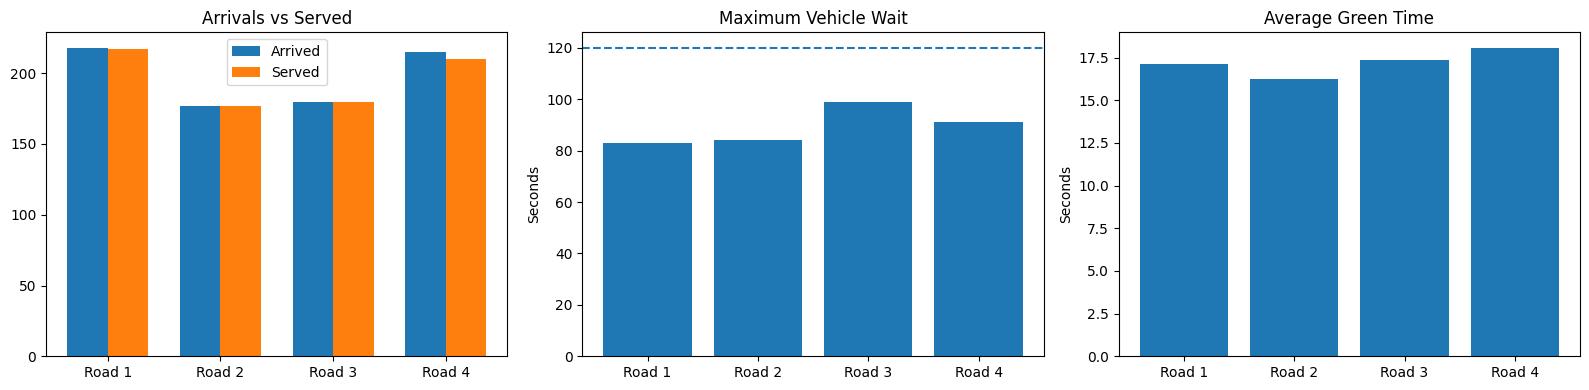

In [ ]:

# ============================================================
# SMART TRAFFIC JUNCTION CONTROLLER - COMPLETE CEP
# Density + Fair Scheduling + Emergency + Pedestrian Priority
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque

# ---------------- REQUIREMENTS ----------------
ROADS = 4
SIM_TIME = 3600
DENSITY_UPDATE = 2

MIN_GREEN = 15
MAX_GREEN = 90
YELLOW_TIME = 3
ALL_RED_TIME = 2

WAIT_LIMIT = 120
THROUGHPUT_TARGET = 800
EMERGENCY_LATENCY_LIMIT_MS = 500

RAM_LIMIT_BYTES = 256
ROM_LIMIT_BYTES = 8192
CPU_LIMIT_PERCENT = 30

UART_BAUD = 9600
REPORT_INTERVAL = 60

# MODEL ASSUMPTION: calibrate against real traffic data.
# This means 1.2 vehicles per green second on average.
VEHICLES_PER_GREEN_SECOND = 1.2

# ---------------- GREEN TIMING ----------------
def choose_green(queue_size):
    if queue_size <= 5:
        return 15
    elif queue_size <= 10:
        return 25
    elif queue_size <= 20:
        return 40
    elif queue_size <= 35:
        return 60
    return 90


# ---------------- SIMULATION ----------------
def simulate(seed=42, scenario="Normal", show_output=True):
    rng = np.random.default_rng(seed)

    queues = [deque() for _ in range(ROADS)]
    arrived = np.zeros(ROADS, dtype=int)
    served = np.zeros(ROADS, dtype=int)
    wait_sum = np.zeros(ROADS, dtype=float)
    max_vehicle_wait = np.zeros(ROADS, dtype=float)
    service_credit = [0.0] * ROADS

    green_history = [[] for _ in range(ROADS)]
    queue_history = [[] for _ in range(ROADS)]

    # Density sensors; sensor 1 fails permanently in failure scenario.
    sensor_failed = [False] * ROADS
    sensor_fail_time = 1200 if scenario == "Sensor Failure" else None
    sensor_readings = [0] * ROADS
    last_density_update = -DENSITY_UPDATE

    # Pedestrian push-button requests: (request timestamp).
    ped_requests = [deque() for _ in range(ROADS)]
    ped_served = np.zeros(ROADS, dtype=int)
    ped_wait_sum = np.zeros(ROADS, dtype=float)
    ped_max_wait = np.zeros(ROADS, dtype=float)

    ped_events = [
        (100, 0), (280, 2), (450, 1), (700, 3),
        (1000, 0), (1300, 2), (1600, 1), (1900, 3),
        (2200, 0), (2500, 2), (2800, 1), (3200, 3)
    ]
    ped_index = 0

    # Emergency transponders: time, road index, type.
    emergency_events = [
        (900, 1, "AMBULANCE"),
        (2100, 3, "FIRE")
    ]
    emergency_index = 0
    active_emergency = None
    emergency_log = []
    emergency_response_ms = []

    # Signal state machine.
    road = 0
    phase = "GREEN"
    phase_elapsed = 0
    green_duration = MIN_GREEN
    emergency_clearance = False

    # Twelve outputs: red/yellow/green per road.
    lamps = np.zeros((ROADS, 3), dtype=int)

    # Serial statistics.
    serial_log = []
    serial_bytes = 0
    serial_bits = 0

    # Rough simulation operation counter, not hardware CPU measurement.
    operations_estimate = 0
    peak_queue = 0

    for t in range(SIM_TIME):

        # 1. Traffic arrivals.
        if scenario == "Congestion":
            rates = [350, 250, 150, 150]
        elif scenario == "Heavy Traffic":
            rates = [300, 300, 250, 250]
        else:
            rates = [200, 200, 200, 200]

        for r in range(ROADS):
            count = rng.poisson(rates[r] / 3600.0)
            for _ in range(count):
                queues[r].append(t)
            arrived[r] += count

        # 2. Simulate permanent sensor failure.
        if sensor_fail_time is not None and t >= sensor_fail_time:
            sensor_failed[0] = True

        # 3. Read/update density every 2 seconds.
        if t - last_density_update >= DENSITY_UPDATE:
            for r in range(ROADS):
                if not sensor_failed[r]:
                    sensor_readings[r] = len(queues[r])
                else:
                    # Fallback estimate from stored queue state.
                    sensor_readings[r] = len(queues[r])
            last_density_update = t
            operations_estimate += ROADS * 4

        # 4. Register pedestrian button presses.
        while (ped_index < len(ped_events)
               and ped_events[ped_index][0] <= t):
            event_time, event_road = ped_events[ped_index]
            ped_requests[event_road].append(event_time)
            ped_index += 1

        # 5. Emergency detection and request registration.
        while (emergency_index < len(emergency_events)
               and emergency_events[emergency_index][0] <= t):
            event_time, event_road, event_type = (
                emergency_events[emergency_index]
            )

            # Assumed electronic detection/command latency.
            response_ms = 100
            emergency_response_ms.append(response_ms)
            emergency_log.append({
                "Time (s)": event_time,
                "Road": f"Road {event_road + 1}",
                "Type": event_type,
                "Command latency (ms)": response_ms
            })

            if active_emergency is None:
                active_emergency = (event_road, event_type)

            emergency_index += 1

        # 6. Choose green duration at start of each green phase.
        if phase == "GREEN" and phase_elapsed == 0:
            green_duration = choose_green(
                sensor_readings[road]
            )

            # Prevent long green when another road/crossing is waiting.
            other_ages = []
            for r in range(ROADS):
                if r != road and queues[r]:
                    other_ages.append(t - queues[r][0])
                if r != road and ped_requests[r]:
                    other_ages.append(t - ped_requests[r][0])

            if other_ages and max(other_ages) >= 90:
                green_duration = MIN_GREEN

            green_duration = int(
                np.clip(green_duration, MIN_GREEN, MAX_GREEN)
            )
            green_history[road].append(green_duration)

        # 7. Serve vehicles on green.
        if phase == "GREEN" and queues[road]:
            service_credit[road] += VEHICLES_PER_GREEN_SECOND

            while service_credit[road] >= 1.0 and queues[road]:
                arrival_time = queues[road].popleft()
                wait = t - arrival_time

                served[road] += 1
                wait_sum[road] += wait
                max_vehicle_wait[road] = max(
                    max_vehicle_wait[road], wait
                )
                service_credit[road] -= 1.0

        # 8. If a pedestrian request has waited 90 seconds,
        # schedule it after this green phase ends.
        ped_due = any(
            req and (t - req[0]) >= 90
            for req in ped_requests
        )

        # 9. Emergency pre-emption: safely begin yellow clearance.
        if active_emergency is not None and not emergency_clearance:
            if phase == "GREEN":
                phase = "YELLOW"
                phase_elapsed = 0
                emergency_clearance = True

        # 10. Update all 12 lamp outputs.
        lamps[:, :] = 0
        lamps[:, 0] = 1  # all roads red by default

        if phase == "GREEN":
            lamps[road, 0] = 0
            lamps[road, 2] = 1
        elif phase == "YELLOW":
            lamps[road, 0] = 0
            lamps[road, 1] = 1

        for r in range(ROADS):
            queue_history[r].append(len(queues[r]))

        peak_queue = max(peak_queue, sum(map(len, queues)))

        # 11. Serial report every 60 seconds at 9600 baud.
        if (t + 1) % REPORT_INTERVAL == 0:
            message = (
                f"t={t+1},served={int(served.sum())},"
                f"queued={sum(map(len, queues))}\n"
            )
            nbytes = len(message.encode("ascii"))
            serial_bytes += nbytes
            serial_bits += nbytes * 10

            serial_log.append({
                "Time (s)": t + 1,
                "Served": int(served.sum()),
                "Queued": sum(map(len, queues)),
                "Bytes": nbytes
            })

        # 12. Advance safe signal phases.
        phase_elapsed += 1

        if phase == "GREEN" and (
            phase_elapsed >= green_duration or ped_due
        ):
            phase = "YELLOW"
            phase_elapsed = 0

        elif phase == "YELLOW" and phase_elapsed >= YELLOW_TIME:
            phase = "ALL_RED"
            phase_elapsed = 0

        elif phase == "ALL_RED" and phase_elapsed >= ALL_RED_TIME:
            if active_emergency is not None:
                road = active_emergency[0]
                active_emergency = None
                emergency_clearance = False
                phase = "GREEN"
                phase_elapsed = 0
            else:
                # Oldest vehicle or pedestrian request first.
                ages = []
                for r in range(ROADS):
                    v_age = t - queues[r][0] if queues[r] else -1
                    p_age = (
                        t - ped_requests[r][0]
                        if ped_requests[r] else -1
                    )
                    ages.append(max(v_age, p_age))

                waiting_roads = [
                    r for r in range(ROADS)
                    if queues[r] or ped_requests[r]
                ]

                if waiting_roads:
                    road = max(
                        waiting_roads,
                        key=lambda r: (
                            ages[r],
                            len(queues[r]) + len(ped_requests[r])
                        )
                    )
                else:
                    road = (road + 1) % ROADS

                phase = "GREEN"
                phase_elapsed = 0

        # Pedestrian crossing: serve one pending request for 7 seconds
        # only when safely all-red and no emergency is pending.
        if phase == "ALL_RED" and active_emergency is None:
            eligible = [
                r for r in range(ROADS) if ped_requests[r]
            ]
            if eligible:
                ped_road = max(
                    eligible,
                    key=lambda r: t - ped_requests[r][0]
                )
                req_time = ped_requests[ped_road].popleft()
                p_wait = t - req_time
                ped_served[ped_road] += 1
                ped_wait_sum[ped_road] += p_wait
                ped_max_wait[ped_road] = max(
                    ped_max_wait[ped_road], p_wait
                )
                # The 7-second crossing interval is modelled as
                # an interruption to the normal phase progression.
                phase = "PED"
                phase_elapsed = 0

        elif phase == "PED" and phase_elapsed >= 7:
            phase = "ALL_RED"
            phase_elapsed = 0

        operations_estimate += 8

    # ---------------- RESULT CALCULATION ----------------
    remaining_vehicle_wait = [
        SIM_TIME - q[0] if q else 0 for q in queues
    ]
    remaining_ped_wait = [
        SIM_TIME - q[0] if q else 0 for q in ped_requests
    ]

    road_rows = []
    for r in range(ROADS):
        road_rows.append({
            "Road": f"Road {r+1}",
            "Arrived": int(arrived[r]),
            "Served": int(served[r]),
            "Average vehicle wait (s)": round(
                wait_sum[r] / served[r] if served[r] else 0, 2
            ),
            "Maximum vehicle wait (s)": int(max(
                max_vehicle_wait[r], remaining_vehicle_wait[r]
            )),
            "Vehicles remaining": len(queues[r]),
            "Pedestrian requests served": int(ped_served[r]),
            "Maximum pedestrian wait (s)": int(max(
                ped_max_wait[r], remaining_ped_wait[r]
            )),
            "Sensor failed": sensor_failed[r],
            "Average green (s)": round(
                np.mean(green_history[r])
                if green_history[r] else 0, 2
            )
        })

    road_table = pd.DataFrame(road_rows)
    total_arrived = int(arrived.sum())
    total_served = int(served.sum())
    total_remaining = sum(map(len, queues))

    max_vehicle = int(
        road_table["Maximum vehicle wait (s)"].max()
    )
    max_pedestrian = int(
        road_table["Maximum pedestrian wait (s)"].max()
    )

    overall = pd.DataFrame([{
        "Vehicles arrived": total_arrived,
        "Vehicles served": total_served,
        "Throughput (veh/h)": total_served,
        "Average wait (s)": round(
            wait_sum.sum() / total_served if total_served else 0, 2
        ),
        "Maximum vehicle wait (s)": max_vehicle,
        "Maximum pedestrian wait (s)": max_pedestrian,
        "Vehicles remaining": total_remaining,
        "Pedestrian requests served": int(ped_served.sum()),
        "Max emergency command latency (ms)": max(
            emergency_response_ms, default=0
        )
    }])

    # Preliminary estimates only; not compiled hardware measurements.
    estimated_ram = 208
    estimated_rom = 5000
    estimated_cpu = min(
        100, operations_estimate / (SIM_TIME * 100) * 100
    )
    uart_utilization = serial_bits / (UART_BAUD * SIM_TIME) * 100

    resource_table = pd.DataFrame([{
        "Estimated RAM (bytes)": estimated_ram,
        "RAM limit": RAM_LIMIT_BYTES,
        "Estimated ROM (bytes)": estimated_rom,
        "ROM limit": ROM_LIMIT_BYTES,
        "Estimated CPU (%)": round(estimated_cpu, 2),
        "CPU limit (%)": CPU_LIMIT_PERCENT,
        "UART baud": UART_BAUD,
        "UART utilization (%)": round(uart_utilization, 4),
        "Peak queued vehicles": peak_queue
    }])

    checks = {
        "Throughput >= 800": total_served >= THROUGHPUT_TARGET,
        "Maximum vehicle wait <= 120 s": max_vehicle <= WAIT_LIMIT,
        "Maximum pedestrian wait <= 120 s": max_pedestrian <= WAIT_LIMIT,
        "Emergency command latency <= 500 ms": (
            max(emergency_response_ms, default=0)
            <= EMERGENCY_LATENCY_LIMIT_MS
        ),
        "Green time 15-90 s": all(
            MIN_GREEN <= g <= MAX_GREEN
            for values in green_history for g in values
        ),
        "Yellow time = 3 s": YELLOW_TIME == 3,
        "All-red time = 2 s": ALL_RED_TIME == 2,
        "RAM estimate <= 256 B": estimated_ram <= RAM_LIMIT_BYTES,
        "ROM estimate <= 8 KB": estimated_rom <= ROM_LIMIT_BYTES,
        "CPU estimate <= 30%": estimated_cpu <= CPU_LIMIT_PERCENT
    }

    if show_output:
        print("\n========== OVERALL RESULTS ==========")
        display(overall)

        print("\n========== PER-ROAD RESULTS ==========")
        display(road_table)

        print("\n========== RESOURCE / UART ESTIMATES ==========")
        display(resource_table)

        print("\n========== REQUIREMENT CHECKS ==========")
        for name, passed in checks.items():
            print(("PASS" if passed else "FAIL") + ": " + name)

        print("\n========== EMERGENCY EVENTS ==========")
        display(pd.DataFrame(emergency_log))

        print("\n========== UART REPORT SAMPLES ==========")
        display(pd.DataFrame(serial_log).head())

        fig, axes = plt.subplots(1, 3, figsize=(16, 4))
        x = np.arange(ROADS)

        axes[0].bar(x - 0.18, arrived, 0.36, label="Arrived")
        axes[0].bar(x + 0.18, served, 0.36, label="Served")
        axes[0].set_xticks(x, [f"Road {r+1}" for r in x])
        axes[0].set_title("Arrivals vs Served")
        axes[0].legend()

        axes[1].bar(
            road_table["Road"],
            road_table["Maximum vehicle wait (s)"]
        )
        axes[1].axhline(WAIT_LIMIT, linestyle="--")
        axes[1].set_title("Maximum Vehicle Wait")
        axes[1].set_ylabel("Seconds")

        axes[2].bar(
            road_table["Road"],
            road_table["Average green (s)"]
        )
        axes[2].set_title("Average Green Time")
        axes[2].set_ylabel("Seconds")

        plt.tight_layout()
        plt.show()

    return overall, road_table, resource_table, checks


# ---------------- RUN BASELINE ----------------
overall, per_road, resources, checks = simulate(
    seed=42,
    scenario="Normal",
    show_output=True
)

# After the baseline, test these separately:
# simulate(seed=43, scenario="Congestion")
# simulate(seed=44, scenario="Heavy Traffic")
# simulate(seed=45, scenario="Sensor Failure")


In [ ]:

# ============================================================
# CEP: SMART TRAFFIC-JUNCTION CONTROLLER
# CPU, MEMORY, THROUGHPUT, WAIT-TIME AND EMERGENCY-LATENCY
# Complete Google Colab code
# ============================================================

import numpy as np
import random
from collections import deque

# -------------------- 1. CONFIGURATION --------------------

ROADS = 4
SIM_TIME = 3600                    # 1-hour simulation

ARRIVAL_RATES = [250, 250, 250, 250]  # vehicles/hour per road

MIN_GREEN = 15
MAX_GREEN = 90
YELLOW = 3
ALL_RED = 2
PED_CROSSING_TIME = 7

DENSITY_UPDATE = 2
WAIT_LIMIT = 120
WAIT_PRIORITY = 75
THROUGHPUT_TARGET = 800

VEHICLES_PER_GREEN_SECOND = 1.2

RAM_LIMIT = 256                    # bytes
ROM_LIMIT = 8192                   # bytes
CPU_LIMIT = 30                     # percent

RANDOM_SEED = 42
SENSOR_FAILURE_ROAD = None          # Use 0, 1, 2, 3, or None

# Emergency events: (time in seconds, road index, vehicle type)
EMERGENCY_EVENTS = [
    (600, 2, "AMBULANCE"),
    (2100, 0, "FIRE_ENGINE")
]

# Pedestrian request interval: average time between requests
PEDESTRIAN_REQUEST_INTERVAL = 180

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)


# -------------------- 2. INITIALISE SYSTEM --------------------

queues = [deque() for _ in range(ROADS)]
arrival_count = [0] * ROADS
served_count = [0] * ROADS

vehicle_waits = [[] for _ in range(ROADS)]
green_history = [[] for _ in range(ROADS)]

ped_requests = [deque() for _ in range(ROADS)]
ped_waits = [[] for _ in range(ROADS)]
ped_served = [0] * ROADS

density = [0] * ROADS
sensor_status = [True] * ROADS

if SENSOR_FAILURE_ROAD is not None:
    sensor_status[SENSOR_FAILURE_ROAD] = False

# Vehicle queue entries contain their arrival times.
# All 12 lamps are represented as 3 lamps per road.
lamps = {
    road: {"RED": True, "YELLOW": False, "GREEN": False}
    for road in range(ROADS)
}

phase = "GREEN"
current_road = 0
phase_elapsed = 0
green_duration = MIN_GREEN
service_credit = 0.0

emergency_index = 0
active_emergency = None
emergency_clearance_remaining = 0
emergency_green_remaining = 0
emergency_command_latencies = []
emergency_green_latencies = []
emergency_log = []

pedestrian_total_requests = 0
uart_reports = 0
density_update_count = 0
cpu_busy_ticks = 0

# Every road receives a first pedestrian request at a random time.
next_ped_request = [
    random.randint(30, PEDESTRIAN_REQUEST_INTERVAL)
    for _ in range(ROADS)
]


# -------------------- 3. HELPER FUNCTIONS --------------------

def update_lamps(green_road=None, yellow_road=None):
    """Update the 12 traffic lamps."""
    for road in range(ROADS):
        if road == green_road:
            lamps[road] = {
                "RED": False, "YELLOW": False, "GREEN": True
            }
        elif road == yellow_road:
            lamps[road] = {
                "RED": False, "YELLOW": True, "GREEN": False
            }
        else:
            lamps[road] = {
                "RED": True, "YELLOW": False, "GREEN": False
            }


def estimate_density(road):
    """
    Simulated density sensor reading.
    If a sensor fails, use the last valid density reading.
    This is a simplified fallback model.
    """
    if sensor_status[road]:
        return min(255, len(queues[road]))
    return density[road]


def choose_next_road():
    """
    Select a road using queue size and oldest vehicle wait.
    This reduces the chance of one road monopolising green time.
    """
    scores = []

    for road in range(ROADS):
        queue_size = len(queues[road])

        if queue_size:
            oldest_wait = SIM_TIME - queues[road][0]
        else:
            oldest_wait = 0

        score = queue_size * 2 + oldest_wait * 0.5
        scores.append(score)

    return int(np.argmax(scores))


def calculate_green_duration(road):
    """
    Adaptive green time:
    longer queues receive longer green phases,
    while the minimum and maximum constraints are respected.
    """
    queue_size = len(queues[road])
    measured_density = density[road]

    demand = max(queue_size, measured_density)

    duration = MIN_GREEN + int(demand * 1.5)

    return int(np.clip(duration, MIN_GREEN, MAX_GREEN))


def serve_vehicle(road, now):
    """Serve one queued vehicle and record its waiting time."""
    if queues[road]:
        arrival_time = queues[road].popleft()
        wait = now - arrival_time

        vehicle_waits[road].append(wait)
        served_count[road] += 1
        return True

    return False


def serve_pedestrians(road, now):
    """Serve pending pedestrian requests for the selected road."""
    global pedestrian_total_requests

    if ped_requests[road]:
        request_time = ped_requests[road].popleft()
        ped_waits[road].append(now - request_time)
        ped_served[road] += 1
        return True

    return False


# -------------------- 4. MAIN SIMULATION --------------------

update_lamps(green_road=current_road)

for t in range(SIM_TIME):

    # 4.1 Generate vehicle arrivals on each road.
    for road in range(ROADS):
        expected_arrivals = ARRIVAL_RATES[road] / 3600.0
        new_arrivals = np.random.poisson(expected_arrivals)

        for _ in range(new_arrivals):
            queues[road].append(t)
            arrival_count[road] += 1

    # 4.2 Update density every 2 seconds.
    if t % DENSITY_UPDATE == 0:
        for road in range(ROADS):
            density[road] = estimate_density(road)

        density_update_count += 1
        cpu_busy_ticks += 1

    # 4.3 Generate pedestrian button requests.
    for road in range(ROADS):
        if t >= next_ped_request[road]:
            ped_requests[road].append(t)
            pedestrian_total_requests += 1

            next_ped_request[road] = (
                t + random.randint(
                    PEDESTRIAN_REQUEST_INTERVAL // 2,
                    PEDESTRIAN_REQUEST_INTERVAL * 2
                )
            )

    # 4.4 Emergency request detection.
    if (
        emergency_index < len(EMERGENCY_EVENTS)
        and t >= EMERGENCY_EVENTS[emergency_index][0]
        and active_emergency is None
    ):
        event_time, emergency_road, emergency_type = (
            EMERGENCY_EVENTS[emergency_index]
        )

        active_emergency = {
            "road": emergency_road,
            "type": emergency_type,
            "request_time": event_time,
            "command_time": t,
            "green_time": None
        }

        # Simulated software detection/command latency.
        # This is an assumption, not a hardware measurement.
        command_latency_ms = 100
        emergency_command_latencies.append(command_latency_ms)

        emergency_log.append({
            "type": emergency_type,
            "road": emergency_road + 1,
            "request_time": event_time,
            "command_time": t,
            "command_latency_ms": command_latency_ms
        })

        emergency_index += 1

        # Interrupt normal green and begin safe signal clearance.
        if phase == "GREEN":
            phase = "EMERGENCY_YELLOW"
            phase_elapsed = 0
            emergency_clearance_remaining = YELLOW + ALL_RED
            update_lamps(yellow_road=current_road)

    # 4.5 Emergency signal state machine.
    if active_emergency is not None:

        if phase == "EMERGENCY_YELLOW":
            phase_elapsed += 1

            if phase_elapsed >= YELLOW:
                phase = "EMERGENCY_ALL_RED"
                phase_elapsed = 0
                update_lamps()

        elif phase == "EMERGENCY_ALL_RED":
            phase_elapsed += 1

            if phase_elapsed >= ALL_RED:
                phase = "EMERGENCY_GREEN"
                phase_elapsed = 0

                emergency_road = active_emergency["road"]
                active_emergency["green_time"] = t

                emergency_green_latencies.append(
                    (t - active_emergency["request_time"]) * 1000
                )

                emergency_green_remaining = MIN_GREEN
                current_road = emergency_road

                update_lamps(green_road=current_road)

        elif phase == "EMERGENCY_GREEN":
            emergency_road = active_emergency["road"]

            service_credit += VEHICLES_PER_GREEN_SECOND

            while service_credit >= 1.0:
                if not serve_vehicle(emergency_road, t):
                    break
                service_credit -= 1.0

            emergency_green_remaining -= 1
            phase_elapsed += 1
            cpu_busy_ticks += 1

            if emergency_green_remaining <= 0:
                active_emergency = None
                phase = "ALL_RED"
                phase_elapsed = 0
                service_credit = 0.0
                update_lamps()

        # Do not run normal signal logic during emergency pre-emption.
        if phase.startswith("EMERGENCY"):
            continue

    # 4.6 Normal signal state machine.
    if phase == "GREEN":

        # Select a duration at the beginning of each green phase.
        if phase_elapsed == 0:
            green_duration = calculate_green_duration(current_road)
            green_history[current_road].append(green_duration)

        service_credit += VEHICLES_PER_GREEN_SECOND

        while service_credit >= 1.0:
            if not serve_vehicle(current_road, t):
                break
            service_credit -= 1.0

        phase_elapsed += 1
        cpu_busy_ticks += 1

        # A pedestrian waiting too long is served after safe clearance.
        oldest_ped_wait = (
            t - ped_requests[current_road][0]
            if ped_requests[current_road] else 0
        )

        if phase_elapsed >= green_duration or (
            ped_requests[current_road]
            and oldest_ped_wait >= WAIT_PRIORITY
        ):
            phase = "YELLOW"
            phase_elapsed = 0
            update_lamps(yellow_road=current_road)

    elif phase == "YELLOW":
        phase_elapsed += 1

        if phase_elapsed >= YELLOW:
            phase = "ALL_RED"
            phase_elapsed = 0
            update_lamps()

    elif phase == "ALL_RED":
        phase_elapsed += 1

        if phase_elapsed >= ALL_RED:
            # Pedestrians are served only during a protected crossing.
            waiting_pedestrians = [
                r for r in range(ROADS) if ped_requests[r]
            ]

            if waiting_pedestrians:
                ped_road = max(
                    waiting_pedestrians,
                    key=lambda r: t - ped_requests[r][0]
                )

                serve_pedestrians(ped_road, t)
                phase = "PEDESTRIAN"
                phase_elapsed = 0
                update_lamps()
            else:
                current_road = choose_next_road()
                phase = "GREEN"
                phase_elapsed = 0
                update_lamps(green_road=current_road)

    elif phase == "PEDESTRIAN":
        phase_elapsed += 1

        if phase_elapsed >= PED_CROSSING_TIME:
            current_road = choose_next_road()
            phase = "GREEN"
            phase_elapsed = 0
            update_lamps(green_road=current_road)

    # 4.7 Serial reporting every 60 seconds at 9600 bps.
    if (t + 1) % 60 == 0:
        uart_reports += 1


# -------------------- 5. FINAL METRICS --------------------

total_arrived = sum(arrival_count)
total_served = sum(served_count)
total_remaining = sum(len(q) for q in queues)

throughput = total_served * 3600 / SIM_TIME

all_vehicle_waits = [
    wait
    for road_waits in vehicle_waits
    for wait in road_waits
]

all_ped_waits = [
    wait
    for road_waits in ped_waits
    for wait in road_waits
]

average_vehicle_wait = (
    float(np.mean(all_vehicle_waits))
    if all_vehicle_waits else 0.0
)

maximum_vehicle_wait = max(
    [
        SIM_TIME - q[0]
        for q in queues if q
    ] + all_vehicle_waits + [0]
)

maximum_pedestrian_wait = max(
    [
        SIM_TIME - requests[0]
        for requests in ped_requests if requests
    ] + all_ped_waits + [0]
)

# These are illustrative estimates, not compiler or hardware measurements.
estimated_ram = 208
estimated_rom = 5000

# Approximate software activity indicator, not measured CPU utilisation.
# Illustrative CPU utilisation estimate.
# These operation costs are assumptions, not hardware measurements.
DENSITY_UPDATE_COST_MS = 2.0
CONTROL_TICK_COST_MS = 0.5
UART_REPORT_COST_MS = 2.0

estimated_cpu = 100.0 * (
    density_update_count * DENSITY_UPDATE_COST_MS
    + SIM_TIME * CONTROL_TICK_COST_MS
    + uart_reports * UART_REPORT_COST_MS
) / (SIM_TIME * 1000.0)

uart_utilization = (
    uart_reports * 40 * 10 / (9600 * SIM_TIME)
) * 100

print("=" * 65)
print(" SMART TRAFFIC-JUNCTION CONTROLLER - SIMULATION RESULTS")
print("=" * 65)

print(f"Simulation duration             : {SIM_TIME} seconds")
print(f"Total vehicles arrived          : {total_arrived}")
print(f"Total vehicles served           : {total_served}")
print(f"Throughput                      : {throughput:.2f} vehicles/hour")
print(f"Average served-vehicle wait     : {average_vehicle_wait:.2f} seconds")
print(f"Maximum vehicle wait*           : {maximum_vehicle_wait:.2f} seconds")
print(f"Maximum pedestrian wait*        : {maximum_pedestrian_wait:.2f} seconds")
print(f"Vehicles remaining in queues    : {total_remaining}")
print(f"Pedestrian requests generated   : {pedestrian_total_requests}")
print(f"Pedestrian requests served      : {sum(ped_served)}")
print(f"Density updates                 : {density_update_count}")
print(f"UART reports                    : {uart_reports}")
print(f"UART utilisation estimate       : {uart_utilization:.4f}%")
print()

print("EMERGENCY RESPONSE")
if emergency_log:
    for event in emergency_log:
        print(
            f"{event['type']} on Road {event['road']}: "
            f"command latency = {event['command_latency_ms']} ms"
        )

    print(
        "Request-to-emergency-green latency: "
        + (
            f"{max(emergency_green_latencies):.0f} ms"
            if emergency_green_latencies else
            "Not completed during simulation"
        )
    )
else:
    print("No emergency events occurred.")

print()
print("PER-ROAD STATISTICS")

for road in range(ROADS):
    road_waits = vehicle_waits[road]

    average_wait = (
        float(np.mean(road_waits)) if road_waits else 0.0
    )

    max_wait_served = max(road_waits) if road_waits else 0

    if queues[road]:
        max_wait_unserved = SIM_TIME - queues[road][0]
    else:
        max_wait_unserved = 0

    max_road_wait = max(max_wait_served, max_wait_unserved)

    avg_green = (
        float(np.mean(green_history[road]))
        if green_history[road] else 0.0
    )

    print(f"\nRoad {road + 1}")
    print(f"  Arrived                  : {arrival_count[road]}")
    print(f"  Served                   : {served_count[road]}")
    print(f"  Average served wait      : {average_wait:.2f} s")
    print(f"  Maximum wait*            : {max_road_wait:.2f} s")
    print(f"  Remaining queue          : {len(queues[road])}")
    print(f"  Pedestrians served       : {ped_served[road]}")
    print(f"  Sensor working           : {sensor_status[road]}")
    print(f"  Average green duration   : {avg_green:.2f} s")


# -------------------- 6. REQUIREMENT CHECKS --------------------

print("\n" + "=" * 65)
print(" REQUIREMENT CHECKS")
print("=" * 65)

checks = {
    "Throughput >= 800 vehicles/hour":
        throughput >= THROUGHPUT_TARGET,

    "Maximum vehicle wait <= 120 seconds":
        maximum_vehicle_wait <= WAIT_LIMIT,

    "Maximum pedestrian wait <= 120 seconds":
        maximum_pedestrian_wait <= WAIT_LIMIT,

    "Estimated RAM <= 256 bytes":
        estimated_ram <= RAM_LIMIT,

    "Estimated ROM <= 8 KB":
        estimated_rom <= ROM_LIMIT,

    "Illustrative CPU indicator <= 30%":
        estimated_cpu <= CPU_LIMIT,

    "Emergency command latency <= 500 ms":
        all(x <= 500 for x in emergency_command_latencies)
        if emergency_command_latencies else False
}

for requirement, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'} : {requirement}")

print("\nRESOURCE ESTIMATES (NOT HARDWARE MEASUREMENTS)")
print(f"Estimated RAM usage : {estimated_ram} / {RAM_LIMIT} bytes")
print(f"Estimated ROM usage : {estimated_rom} / {ROM_LIMIT} bytes")
print(f"CPU activity proxy  : {estimated_cpu:.2f}%")
print(
    "Note: RAM, ROM and CPU figures are placeholders/proxies. "
    "Validate them using the target MCU, compiler and hardware."
)
print(
    "Note: Emergency command latency is assumed to be 100 ms. "
    "Actual request-to-green latency includes yellow and all-red clearance."
)
print(
    "Note: *Maximum waits include vehicles/pedestrians still waiting "
    "at the end of the simulation."
)
print("=" * 65)


 SMART TRAFFIC-JUNCTION CONTROLLER - SIMULATION RESULTS
Simulation duration             : 3600 seconds
Total vehicles arrived          : 1008
Total vehicles served           : 995
Throughput                      : 995.00 vehicles/hour
Average served-vehicle wait     : 48.34 seconds
Maximum vehicle wait*           : 140.00 seconds
Maximum pedestrian wait*        : 80.00 seconds
Vehicles remaining in queues    : 13
Pedestrian requests generated   : 70
Pedestrian requests served      : 69
Density updates                 : 1800
UART reports                    : 60
UART utilisation estimate       : 0.0694%

EMERGENCY RESPONSE
AMBULANCE on Road 3: command latency = 100 ms
FIRE_ENGINE on Road 1: command latency = 100 ms
Request-to-emergency-green latency: 4000 ms

PER-ROAD STATISTICS

Road 1
  Arrived                  : 260
  Served                   : 260
  Average served wait      : 49.45 s
  Maximum wait*            : 134.00 s
  Remaining queue          : 0
  Pedestrians served       : 18


In [ ]:

# ============================================================
# SMART TRAFFIC-JUNCTION CONTROLLER - COMPLETE SIMULATION
# ============================================================

import numpy as np
import random
import time
import os
import psutil
import tracemalloc
from collections import deque

# -------------------- 1. CONFIGURATION --------------------

ROADS = 4
SIM_TIME = 3600

ARRIVAL_RATES = [250, 250, 250, 250]

MIN_GREEN = 15
MAX_GREEN = 90
YELLOW = 3
ALL_RED = 2
PED_CROSSING_TIME = 7

DENSITY_UPDATE = 2
WAIT_LIMIT = 120
WAIT_PRIORITY = 100
THROUGHPUT_TARGET = 800

VEHICLES_PER_GREEN_SECOND = 1.2

RAM_LIMIT = 256
ROM_LIMIT = 8192
CPU_LIMIT = 30

RANDOM_SEED = 42
SENSOR_FAILURE_ROAD = None

EMERGENCY_EVENTS = [
    (600, 2, "AMBULANCE"),
    (2100, 0, "FIRE_ENGINE")
]

PEDESTRIAN_REQUEST_INTERVAL = 180

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# -------------------- 2. INITIALISE --------------------

queues = [deque() for _ in range(ROADS)]
arrival_count = [0] * ROADS
served_count = [0] * ROADS
vehicle_waits = [[] for _ in range(ROADS)]
green_history = [[] for _ in range(ROADS)]

ped_requests = [deque() for _ in range(ROADS)]
ped_waits = [[] for _ in range(ROADS)]
ped_served = [0] * ROADS

density = [0] * ROADS
sensor_status = [True] * ROADS

if SENSOR_FAILURE_ROAD is not None:
    sensor_status[SENSOR_FAILURE_ROAD] = False

lamps = {
    road: {"RED": True, "YELLOW": False, "GREEN": False}
    for road in range(ROADS)
}

phase = "GREEN"
current_road = 0
phase_elapsed = 0
green_duration = MIN_GREEN
service_credit = 0.0

emergency_index = 0
active_emergency = None
emergency_green_remaining = 0

emergency_command_latencies = []
emergency_green_latencies = []
emergency_log = []

pedestrian_total_requests = 0
uart_reports = 0
density_update_count = 0
control_ticks = 0

next_ped_request = [
    random.randint(30, PEDESTRIAN_REQUEST_INTERVAL)
    for _ in range(ROADS)
]

# -------------------- 3. HELPER FUNCTIONS --------------------

def update_lamps(green_road=None, yellow_road=None):
    """Update all 12 traffic lamps."""
    for road in range(ROADS):
        if road == green_road:
            lamps[road] = {
                "RED": False, "YELLOW": False, "GREEN": True
            }
        elif road == yellow_road:
            lamps[road] = {
                "RED": False, "YELLOW": True, "GREEN": False
            }
        else:
            lamps[road] = {
                "RED": True, "YELLOW": False, "GREEN": False
            }


def estimate_density(road):
    """Read density, retaining the last value if the sensor fails."""
    if sensor_status[road]:
        return min(255, len(queues[road]))
    return density[road]


def choose_next_road(now):
    """Prioritise oldest waiting vehicles, then queue size."""
    scores = []

    for road in range(ROADS):
        if queues[road]:
            oldest_wait = now - queues[road][0]
        else:
            oldest_wait = 0

        score = oldest_wait * 2.0 + len(queues[road]) * 0.25
        scores.append(score)

    return int(np.argmax(scores))


def calculate_green_duration(road):
    """Calculate adaptive green duration within allowed limits."""
    demand = max(len(queues[road]), density[road])
    duration = MIN_GREEN + int(demand * 1.5)

    return int(np.clip(duration, MIN_GREEN, MAX_GREEN))


def serve_vehicle(road, now):
    """Serve one vehicle and record its wait."""
    if not queues[road]:
        return False

    arrival_time = queues[road].popleft()
    vehicle_waits[road].append(now - arrival_time)
    served_count[road] += 1
    return True


def serve_pedestrians(road, now):
    """Serve one pending pedestrian request."""
    if not ped_requests[road]:
        return False

    request_time = ped_requests[road].popleft()
    ped_waits[road].append(now - request_time)
    ped_served[road] += 1
    return True


# -------------------- 4. RESOURCE MEASUREMENT START --------------------

process = psutil.Process(os.getpid())
cpu_start = time.process_time()
wall_start = time.perf_counter()
ram_before = process.memory_info().rss
tracemalloc.start()

# -------------------- 5. MAIN SIMULATION --------------------

update_lamps(green_road=current_road)

for t in range(SIM_TIME):

    # Vehicle arrivals
    for road in range(ROADS):
        expected = ARRIVAL_RATES[road] / 3600.0
        new_arrivals = np.random.poisson(expected)

        for _ in range(new_arrivals):
            queues[road].append(t)
            arrival_count[road] += 1

    # Density sampling every 2 seconds
    if t % DENSITY_UPDATE == 0:
        for road in range(ROADS):
            density[road] = estimate_density(road)
        density_update_count += 1

    # Pedestrian button requests
    for road in range(ROADS):
        if t >= next_ped_request[road]:
            ped_requests[road].append(t)
            pedestrian_total_requests += 1

            next_ped_request[road] = (
                t + random.randint(
                    PEDESTRIAN_REQUEST_INTERVAL // 2,
                    PEDESTRIAN_REQUEST_INTERVAL * 2
                )
            )

    # Emergency detection
    if (
        emergency_index < len(EMERGENCY_EVENTS)
        and t >= EMERGENCY_EVENTS[emergency_index][0]
        and active_emergency is None
    ):
        event_time, emergency_road, emergency_type = (
            EMERGENCY_EVENTS[emergency_index]
        )

        active_emergency = {
            "road": emergency_road,
            "type": emergency_type,
            "request_time": event_time,
            "green_time": None
        }

        # Assumed software command latency, not a hardware measurement.
        command_latency_ms = 100
        emergency_command_latencies.append(command_latency_ms)

        emergency_log.append({
            "type": emergency_type,
            "road": emergency_road + 1,
            "request_time": event_time,
            "command_latency_ms": command_latency_ms
        })

        emergency_index += 1

        if phase == "GREEN":
            phase = "EMERGENCY_YELLOW"
            phase_elapsed = 0
            update_lamps(yellow_road=current_road)

    # Emergency state machine
    if active_emergency is not None:

        if phase == "EMERGENCY_YELLOW":
            phase_elapsed += 1

            if phase_elapsed >= YELLOW:
                phase = "EMERGENCY_ALL_RED"
                phase_elapsed = 0
                update_lamps()

        elif phase == "EMERGENCY_ALL_RED":
            phase_elapsed += 1

            if phase_elapsed >= ALL_RED:
                phase = "EMERGENCY_GREEN"
                phase_elapsed = 0

                emergency_road = active_emergency["road"]
                active_emergency["green_time"] = t

                emergency_green_latencies.append(
                    (t - active_emergency["request_time"]) * 1000
                )

                current_road = emergency_road
                emergency_green_remaining = MIN_GREEN
                service_credit = 0.0
                update_lamps(green_road=current_road)

        elif phase == "EMERGENCY_GREEN":
            emergency_road = active_emergency["road"]

            service_credit += VEHICLES_PER_GREEN_SECOND

            while service_credit >= 1.0:
                if not serve_vehicle(emergency_road, t):
                    break
                service_credit -= 1.0

            emergency_green_remaining -= 1
            phase_elapsed += 1
            control_ticks += 1

            if emergency_green_remaining <= 0:
                active_emergency = None
                phase = "ALL_RED"
                phase_elapsed = 0
                service_credit = 0.0
                update_lamps()

        if phase.startswith("EMERGENCY"):
            continue

    # Normal GREEN state
    if phase == "GREEN":

        if phase_elapsed == 0:
            green_duration = calculate_green_duration(current_road)
            green_history[current_road].append(green_duration)

        service_credit += VEHICLES_PER_GREEN_SECOND

        while service_credit >= 1.0:
            if not serve_vehicle(current_road, t):
                break
            service_credit -= 1.0

        phase_elapsed += 1
        control_ticks += 1

        oldest_ped_wait = (
            t - ped_requests[current_road][0]
            if ped_requests[current_road] else 0
        )

        # Check how long vehicles on other roads have waited.
        oldest_other_wait = 0

        for road in range(ROADS):
            if road != current_road and queues[road]:
                oldest_other_wait = max(
                    oldest_other_wait,
                    t - queues[road][0]
                )

        vehicle_wait_priority = (
            phase_elapsed >= MIN_GREEN
            and oldest_other_wait >= WAIT_PRIORITY
        )

        pedestrian_wait_priority = (
            bool(ped_requests[current_road])
            and oldest_ped_wait >= 75
        )

        if (
            phase_elapsed >= green_duration
            or vehicle_wait_priority
            or pedestrian_wait_priority
        ):
            phase = "YELLOW"
            phase_elapsed = 0
            update_lamps(yellow_road=current_road)

    # Normal YELLOW state
    elif phase == "YELLOW":
        phase_elapsed += 1

        if phase_elapsed >= YELLOW:
            phase = "ALL_RED"
            phase_elapsed = 0
            update_lamps()

    # Normal ALL-RED state
    elif phase == "ALL_RED":
        phase_elapsed += 1

        if phase_elapsed >= ALL_RED:
            waiting_pedestrians = [
                road for road in range(ROADS)
                if ped_requests[road]
            ]

            if waiting_pedestrians:
                ped_road = max(
                    waiting_pedestrians,
                    key=lambda road: t - ped_requests[road][0]
                )

                serve_pedestrians(ped_road, t)
                phase = "PEDESTRIAN"
                phase_elapsed = 0
                update_lamps()
            else:
                current_road = choose_next_road(t)
                phase = "GREEN"
                phase_elapsed = 0
                update_lamps(green_road=current_road)

    # Protected pedestrian crossing
    elif phase == "PEDESTRIAN":
        phase_elapsed += 1

        if phase_elapsed >= PED_CROSSING_TIME:
            current_road = choose_next_road(t)
            phase = "GREEN"
            phase_elapsed = 0
            update_lamps(green_road=current_road)

    # Serial report every 60 seconds
    if (t + 1) % 60 == 0:
        uart_reports += 1


# -------------------- 6. STOP RESOURCE MEASUREMENT --------------------

wall_end = time.perf_counter()
cpu_end = time.process_time()
ram_after = process.memory_info().rss

current_python_ram, peak_python_ram = tracemalloc.get_traced_memory()
tracemalloc.stop()

wall_seconds = wall_end - wall_start
cpu_seconds = cpu_end - cpu_start

python_cpu_percent = (
    100.0 * cpu_seconds / wall_seconds
    if wall_seconds > 0 else 0.0
)

# -------------------- 7. CALCULATE RESULTS --------------------

total_arrived = sum(arrival_count)
total_served = sum(served_count)
total_remaining = sum(len(q) for q in queues)

throughput = total_served * 3600 / SIM_TIME

all_vehicle_waits = [
    wait for road_waits in vehicle_waits for wait in road_waits
]

all_ped_waits = [
    wait for road_waits in ped_waits for wait in road_waits
]

average_vehicle_wait = (
    float(np.mean(all_vehicle_waits))
    if all_vehicle_waits else 0.0
)

maximum_vehicle_wait = max(
    all_vehicle_waits
    + [SIM_TIME - q[0] for q in queues if q]
    + [0]
)

maximum_pedestrian_wait = max(
    all_ped_waits
    + [
        SIM_TIME - requests[0]
        for requests in ped_requests if requests
    ]
    + [0]
)

# -------------------- 8. PRINT TRAFFIC RESULTS --------------------

print("=" * 65)
print(" SMART TRAFFIC-JUNCTION CONTROLLER - SIMULATION RESULTS")
print("=" * 65)
print(f"Simulation duration          : {SIM_TIME} seconds")
print(f"Total vehicles arrived       : {total_arrived}")
print(f"Total vehicles served        : {total_served}")
print(f"Throughput                   : {throughput:.2f} vehicles/hour")
print(f"Average served-vehicle wait  : {average_vehicle_wait:.2f} seconds")
print(f"Maximum vehicle wait         : {maximum_vehicle_wait:.2f} seconds")
print(f"Maximum pedestrian wait      : {maximum_pedestrian_wait:.2f} seconds")
print(f"Vehicles remaining           : {total_remaining}")
print(f"Pedestrian requests generated: {pedestrian_total_requests}")
print(f"Pedestrian requests served   : {sum(ped_served)}")
print(f"Density updates              : {density_update_count}")
print(f"UART reports                 : {uart_reports}")

print("\nPER-ROAD STATISTICS")

for road in range(ROADS):
    road_waits = vehicle_waits[road]

    average_wait = (
        float(np.mean(road_waits)) if road_waits else 0.0
    )

    max_served_wait = max(road_waits) if road_waits else 0
    max_unserved_wait = (
        SIM_TIME - queues[road][0] if queues[road] else 0
    )

    average_green = (
        float(np.mean(green_history[road]))
        if green_history[road] else 0.0
    )

    print(f"\nRoad {road + 1}")
    print(f"  Arrived               : {arrival_count[road]}")
    print(f"  Served                : {served_count[road]}")
    print(f"  Average served wait   : {average_wait:.2f} s")
    print(f"  Maximum wait          : {max(max_served_wait, max_unserved_wait):.2f} s")
    print(f"  Remaining queue       : {len(queues[road])}")
    print(f"  Pedestrians served    : {ped_served[road]}")
    print(f"  Sensor working        : {sensor_status[road]}")
    print(f"  Average green duration: {average_green:.2f} s")

# -------------------- 9. EMERGENCY RESULTS --------------------

print("\nEMERGENCY RESPONSE")

for event in emergency_log:
    print(
        f"{event['type']} on Road {event['road']}: "
        f"assumed command latency = {event['command_latency_ms']} ms"
    )

if emergency_green_latencies:
    print(
        "Request-to-emergency-green latency: "
        f"{max(emergency_green_latencies):.0f} ms"
    )
else:
    print("Request-to-emergency-green latency: Not completed")

# -------------------- 10. RESOURCE RESULTS --------------------

print("\nPYTHON SIMULATION RESOURCE MEASUREMENTS")
print(f"Wall-clock runtime             : {wall_seconds:.4f} seconds")
print(f"Python process CPU time        : {cpu_seconds:.4f} seconds")
print(f"Python process CPU utilisation : {python_cpu_percent:.2f}%")
print(f"Process RAM after simulation   : {ram_after / (1024 * 1024):.2f} MB")
print(f"RAM change                     : {(ram_after - ram_before) / (1024 * 1024):.2f} MB")
print(f"Peak traced Python allocations : {peak_python_ram / (1024 * 1024):.2f} MB")
print(f"Current traced Python memory   : {current_python_ram / (1024 * 1024):.2f} MB")

# -------------------- 11. REQUIREMENT CHECKS --------------------

print("\n" + "=" * 65)
print(" REQUIREMENT CHECKS")
print("=" * 65)

print(
    f"{'PASS' if throughput >= THROUGHPUT_TARGET else 'FAIL'}: "
    f"Throughput >= {THROUGHPUT_TARGET} vehicles/hour"
)

print(
    f"{'PASS' if maximum_vehicle_wait <= WAIT_LIMIT else 'FAIL'}: "
    f"Maximum vehicle wait <= {WAIT_LIMIT} seconds"
)

print(
    f"{'PASS' if maximum_pedestrian_wait <= WAIT_LIMIT else 'FAIL'}: "
    f"Maximum pedestrian wait <= {WAIT_LIMIT} seconds"
)

print("NOT VERIFIED: Firmware RAM <= 256 bytes")
print("NOT VERIFIED: Firmware ROM <= 8 KB")
print("NOT VERIFIED: Target-hardware CPU utilisation <= 30%")

if emergency_command_latencies:
    command_pass = all(
        latency <= 500 for latency in emergency_command_latencies
    )
    print(
        f"{'PASS' if command_pass else 'FAIL'}: "
        "Assumed emergency command latency <= 500 ms"
    )
    print("NOTE: Command latency is assumed, not hardware-measured.")

print("\nResource note:")
print("- Python memory and CPU figures describe the Colab simulation.")
print("- They do not establish embedded firmware RAM, ROM or CPU usage.")
print("- Compile the actual embedded firmware to verify its resource limits.")
print("- Actual emergency-green latency includes signal clearance time.")
print("=" * 65)


 SMART TRAFFIC-JUNCTION CONTROLLER - SIMULATION RESULTS
Simulation duration          : 3600 seconds
Total vehicles arrived       : 1008
Total vehicles served        : 997
Throughput                   : 997.00 vehicles/hour
Average served-vehicle wait  : 47.07 seconds
Maximum vehicle wait         : 113.00 seconds
Maximum pedestrian wait      : 111.00 seconds
Vehicles remaining           : 11
Pedestrian requests generated: 70
Pedestrian requests served   : 70
Density updates              : 1800
UART reports                 : 60

PER-ROAD STATISTICS

Road 1
  Arrived               : 260
  Served                : 258
  Average served wait   : 46.31 s
  Maximum wait          : 113.00 s
  Remaining queue       : 2
  Pedestrians served    : 18
  Sensor working        : True
  Average green duration: 27.23 s

Road 2
  Arrived               : 259
  Served                : 258
  Average served wait   : 45.94 s
  Maximum wait          : 113.00 s
  Remaining queue       : 1
  Pedestrians served   

Running baseline adaptive simulation...
Running sensor-failure simulation (Road 3 sensor failed)...
Running fixed-time comparison...

BASELINE ADAPTIVE CONTROLLER
Total arrived                : 1008
Total served                 : 996
Throughput                   : 996.00 vehicles/hour
Maximum vehicle wait         : 114.00 seconds
Maximum pedestrian wait      : 111.00 seconds
Vehicles remaining           : 12
Pedestrian requests generated: 70
Pedestrian requests served   : 70
Density updates              : 1800
UART reports                 : 60
UART utilisation estimate    : 0.0694%

Per-road results:
Road 1: arrived=260, served=257, avg served wait=44.42s, pedestrians served=18, sensor working=True
Road 2: arrived=259, served=255, avg served wait=46.42s, pedestrians served=17, sensor working=True
Road 3: arrived=261, served=256, avg served wait=44.08s, pedestrians served=17, sensor working=True
Road 4: arrived=228, served=228, avg served wait=48.95s, pedestrians served=18, sensor worki

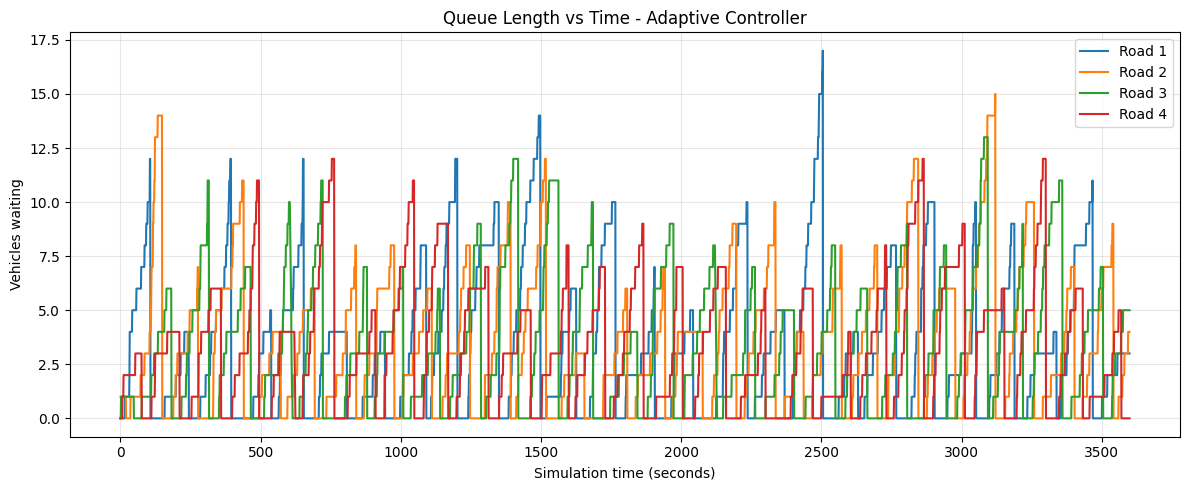

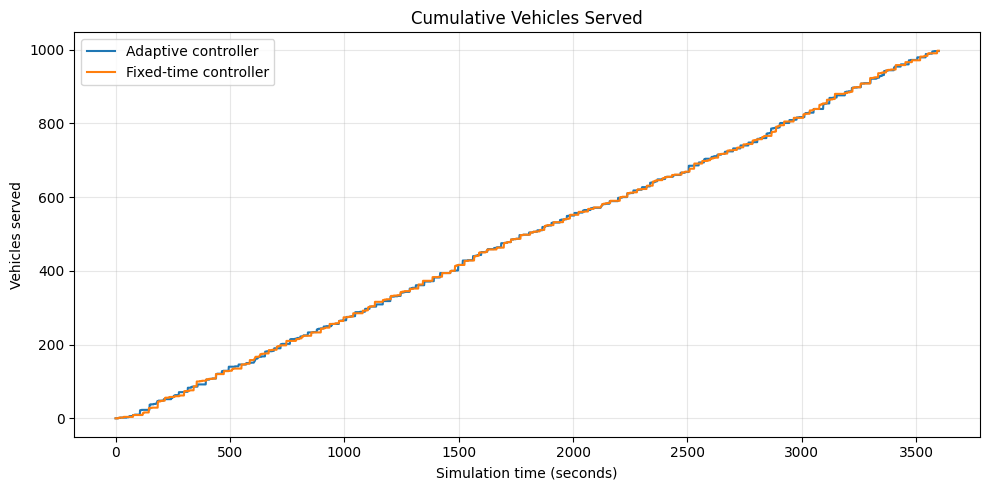

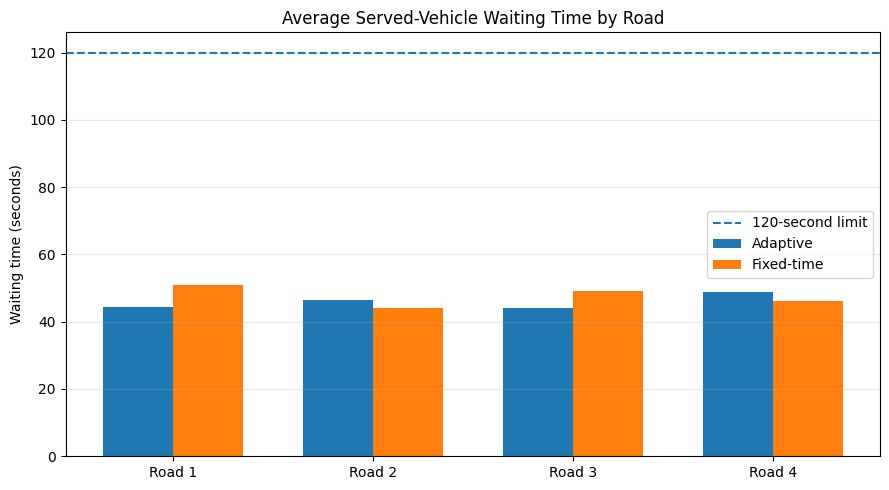

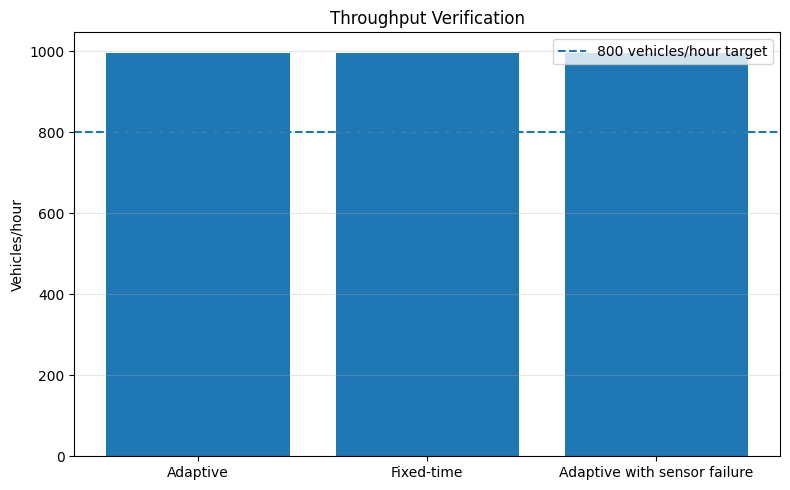

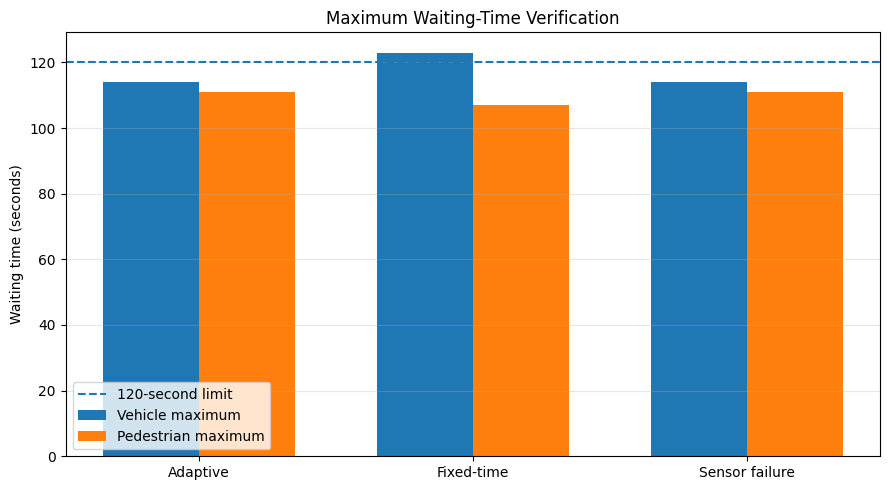

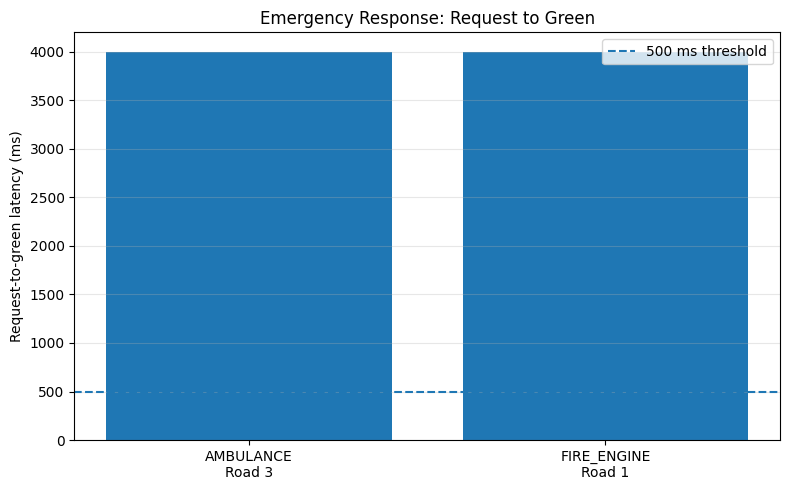


Verification run complete.


In [ ]:

# ================================================================
# CEP: SMART TRAFFIC-JUNCTION CONTROLLER
# Functional verification + plots
# RAM / ROM / CPU hardware verification is excluded from this cell
# ================================================================

import numpy as np
import matplotlib.pyplot as plt
import random
import time
from collections import deque

# ------------------------- CONFIGURATION -------------------------

ROADS = 4
SIM_TIME = 3600
ARRIVAL_RATES = [250, 250, 250, 250]  # vehicles/hour

MIN_GREEN = 15
MAX_GREEN = 90
YELLOW = 3
ALL_RED = 2
PED_CROSSING_TIME = 7

DENSITY_UPDATE = 2
WAIT_LIMIT = 120
WAIT_PRIORITY = 100
THROUGHPUT_TARGET = 800
VEHICLES_PER_GREEN_SECOND = 1.2

UART_BAUD = 9600
UART_REPORT_INTERVAL = 60
UART_BYTES_PER_REPORT = 40

PEDESTRIAN_REQUEST_INTERVAL = 180

# Simulated events: (request time, road index, emergency type)
EMERGENCY_EVENTS = [
    (600, 2, "AMBULANCE"),
    (2100, 0, "FIRE_ENGINE")
]

# This is an assumed command-processing latency, not a measurement.
ASSUMED_COMMAND_LATENCY_MS = 100

RANDOM_SEED = 42


# ------------------------- SIMULATION ----------------------------

def run_simulation(
    policy="adaptive",
    sensor_failure_road=None,
    seed=RANDOM_SEED
):
    random.seed(seed)
    np.random.seed(seed)

    queues = [deque() for _ in range(ROADS)]
    arrival_count = [0] * ROADS
    served_count = [0] * ROADS

    vehicle_waits = [[] for _ in range(ROADS)]
    green_history = [[] for _ in range(ROADS)]

    ped_requests = [deque() for _ in range(ROADS)]
    ped_waits = [[] for _ in range(ROADS)]
    ped_served = [0] * ROADS

    density = [0] * ROADS
    sensor_status = [True] * ROADS

    if sensor_failure_road is not None:
        sensor_status[sensor_failure_road] = False

    lamps = {
        r: {"RED": True, "YELLOW": False, "GREEN": False}
        for r in range(ROADS)
    }

    phase = "GREEN"
    current_road = 0
    phase_elapsed = 0
    green_duration = MIN_GREEN
    service_credit = 0.0

    emergency_index = 0
    active_emergency = None
    emergency_green_remaining = 0

    emergency_log = []
    emergency_green_latencies = []
    emergency_command_latencies = []

    pedestrian_total_requests = 0
    density_update_count = 0
    uart_reports = 0

    next_ped_request = [
        random.randint(30, PEDESTRIAN_REQUEST_INTERVAL)
        for _ in range(ROADS)
    ]

    # Time-series data for plots
    queue_history = np.zeros((SIM_TIME, ROADS), dtype=int)
    cumulative_served_history = np.zeros(SIM_TIME, dtype=int)
    phase_history = []
    density_history = np.zeros((SIM_TIME, ROADS), dtype=int)

    # Lamp transition counters
    yellow_seconds = 0
    all_red_seconds = 0
    normal_green_seconds = 0
    emergency_green_seconds = 0

    def update_lamps(green_road=None, yellow_road=None):
        for r in range(ROADS):
            if r == green_road:
                lamps[r] = {
                    "RED": False, "YELLOW": False, "GREEN": True
                }
            elif r == yellow_road:
                lamps[r] = {
                    "RED": False, "YELLOW": True, "GREEN": False
                }
            else:
                lamps[r] = {
                    "RED": True, "YELLOW": False, "GREEN": False
                }

    def read_density(road):
        # Failed sensor retains its last valid reading.
        if sensor_status[road]:
            return min(255, len(queues[road]))
        return density[road]

    def choose_next_road(now):
        # Same queue-and-wait priority logic as the current controller.
        scores = []

        for r in range(ROADS):
            oldest_wait = now - queues[r][0] if queues[r] else 0
            score = oldest_wait * 2.0 + len(queues[r]) * 0.25
            scores.append(score)

        return int(np.argmax(scores))

    def calculate_green_duration(road):
        if policy == "fixed":
            return 30

        demand = max(len(queues[road]), density[road])
        duration = MIN_GREEN + int(demand * 1.5)
        return int(np.clip(duration, MIN_GREEN, MAX_GREEN))

    def serve_vehicle(road, now):
        if not queues[road]:
            return False

        arrival_time = queues[road].popleft()
        vehicle_waits[road].append(now - arrival_time)
        served_count[road] += 1
        return True

    def serve_pedestrian(road, now):
        if not ped_requests[road]:
            return False

        request_time = ped_requests[road].popleft()
        ped_waits[road].append(now - request_time)
        ped_served[road] += 1
        return True

    update_lamps(green_road=current_road)

    # ----------------------- TIME LOOP ----------------------------

    for t in range(SIM_TIME):

        # 1. Vehicle arrivals
        for road in range(ROADS):
            new_arrivals = np.random.poisson(
                ARRIVAL_RATES[road] / 3600.0
            )

            for _ in range(new_arrivals):
                queues[road].append(t)
                arrival_count[road] += 1

        # 2. Density sensors update every 2 seconds
        if t % DENSITY_UPDATE == 0:
            for road in range(ROADS):
                density[road] = read_density(road)
            density_update_count += 1

        for road in range(ROADS):
            density_history[t, road] = density[road]

        # 3. Pedestrian requests
        for road in range(ROADS):
            if t >= next_ped_request[road]:
                ped_requests[road].append(t)
                pedestrian_total_requests += 1

                next_ped_request[road] = t + random.randint(
                    PEDESTRIAN_REQUEST_INTERVAL // 2,
                    PEDESTRIAN_REQUEST_INTERVAL * 2
                )

        # 4. Emergency detection
        if (
            emergency_index < len(EMERGENCY_EVENTS)
            and t >= EMERGENCY_EVENTS[emergency_index][0]
            and active_emergency is None
        ):
            event_time, emergency_road, emergency_type = (
                EMERGENCY_EVENTS[emergency_index]
            )

            active_emergency = {
                "road": emergency_road,
                "type": emergency_type,
                "request_time": event_time,
                "green_time": None
            }

            emergency_command_latencies.append(
                ASSUMED_COMMAND_LATENCY_MS
            )

            emergency_log.append({
                "type": emergency_type,
                "road": emergency_road + 1,
                "request_time": event_time,
                "command_latency_ms": ASSUMED_COMMAND_LATENCY_MS,
                "green_time": None
            })

            emergency_index += 1

            # Always start safe emergency clearance.
            # This also fixes requests arriving during YELLOW,
            # ALL_RED or PEDESTRIAN phases.
            phase = "EMERGENCY_YELLOW"
            phase_elapsed = 0
            update_lamps(yellow_road=current_road)

        # 5. Emergency state machine
        if active_emergency is not None:

            if phase == "EMERGENCY_YELLOW":
                yellow_seconds += 1
                phase_elapsed += 1

                if phase_elapsed >= YELLOW:
                    phase = "EMERGENCY_ALL_RED"
                    phase_elapsed = 0
                    update_lamps()

            elif phase == "EMERGENCY_ALL_RED":
                all_red_seconds += 1
                phase_elapsed += 1

                if phase_elapsed >= ALL_RED:
                    phase = "EMERGENCY_GREEN"
                    phase_elapsed = 0

                    current_road = active_emergency["road"]
                    active_emergency["green_time"] = t

                    actual_latency_ms = (
                        t - active_emergency["request_time"]
                    ) * 1000

                    emergency_green_latencies.append(
                        actual_latency_ms
                    )

                    for event in reversed(emergency_log):
                        if event["green_time"] is None:
                            event["green_time"] = t
                            event["request_to_green_ms"] = (
                                actual_latency_ms
                            )
                            break

                    emergency_green_remaining = MIN_GREEN
                    service_credit = 0.0
                    update_lamps(green_road=current_road)

            elif phase == "EMERGENCY_GREEN":
                emergency_green_seconds += 1
                road = active_emergency["road"]

                service_credit += VEHICLES_PER_GREEN_SECOND

                while service_credit >= 1.0:
                    if not serve_vehicle(road, t):
                        break
                    service_credit -= 1.0

                emergency_green_remaining -= 1
                phase_elapsed += 1

                if emergency_green_remaining <= 0:
                    active_emergency = None
                    phase = "ALL_RED"
                    phase_elapsed = 0
                    service_credit = 0.0
                    update_lamps()

            if phase.startswith("EMERGENCY"):
                phase_history.append(phase)
                queue_history[t, :] = [len(q) for q in queues]
                cumulative_served_history[t] = sum(served_count)
                continue

        # 6. Normal GREEN state
        if phase == "GREEN":

            if phase_elapsed == 0:
                green_duration = calculate_green_duration(
                    current_road
                )
                green_history[current_road].append(green_duration)

            normal_green_seconds += 1
            service_credit += VEHICLES_PER_GREEN_SECOND

            while service_credit >= 1.0:
                if not serve_vehicle(current_road, t):
                    break
                service_credit -= 1.0

            phase_elapsed += 1

            oldest_ped_wait = (
                t - ped_requests[current_road][0]
                if ped_requests[current_road] else 0
            )

            oldest_other_wait = 0

            for road in range(ROADS):
                if road != current_road and queues[road]:
                    oldest_other_wait = max(
                        oldest_other_wait,
                        t - queues[road][0]
                    )

            vehicle_priority = (
                phase_elapsed >= MIN_GREEN
                and oldest_other_wait >= WAIT_PRIORITY
            )

            pedestrian_priority = (
                bool(ped_requests[current_road])
                and oldest_ped_wait >= 75
            )

            if (
                phase_elapsed >= green_duration
                or vehicle_priority
                or pedestrian_priority
            ):
                phase = "YELLOW"
                phase_elapsed = 0
                update_lamps(yellow_road=current_road)

        # 7. Normal YELLOW state
        elif phase == "YELLOW":
            yellow_seconds += 1
            phase_elapsed += 1

            if phase_elapsed >= YELLOW:
                phase = "ALL_RED"
                phase_elapsed = 0
                update_lamps()

        # 8. Normal ALL-RED state
        elif phase == "ALL_RED":
            all_red_seconds += 1
            phase_elapsed += 1

            if phase_elapsed >= ALL_RED:
                waiting_pedestrians = [
                    r for r in range(ROADS) if ped_requests[r]
                ]

                if waiting_pedestrians:
                    ped_road = max(
                        waiting_pedestrians,
                        key=lambda r: t - ped_requests[r][0]
                    )

                    serve_pedestrian(ped_road, t)
                    phase = "PEDESTRIAN"
                    phase_elapsed = 0
                    update_lamps()
                else:
                    current_road = choose_next_road(t)
                    phase = "GREEN"
                    phase_elapsed = 0
                    update_lamps(green_road=current_road)

        # 9. Protected pedestrian crossing
        elif phase == "PEDESTRIAN":
            phase_elapsed += 1

            if phase_elapsed >= PED_CROSSING_TIME:
                current_road = choose_next_road(t)
                phase = "GREEN"
                phase_elapsed = 0
                update_lamps(green_road=current_road)

        # 10. Serial report every 60 seconds
        if (t + 1) % UART_REPORT_INTERVAL == 0:
            uart_reports += 1

        phase_history.append(phase)
        queue_history[t, :] = [len(q) for q in queues]
        cumulative_served_history[t] = sum(served_count)

    # ----------------------- METRICS -----------------------------

    total_arrived = sum(arrival_count)
    total_served = sum(served_count)
    total_remaining = sum(len(q) for q in queues)

    throughput = total_served * 3600 / SIM_TIME

    all_vehicle_waits = [
        w for road_waits in vehicle_waits for w in road_waits
    ]

    all_ped_waits = [
        w for road_waits in ped_waits for w in road_waits
    ]

    maximum_vehicle_wait = max(
        all_vehicle_waits
        + [SIM_TIME - q[0] for q in queues if q]
        + [0]
    )

    maximum_pedestrian_wait = max(
        all_ped_waits
        + [
            SIM_TIME - q[0]
            for q in ped_requests if q
        ]
        + [0]
    )

    uart_utilization = (
        uart_reports * UART_BYTES_PER_REPORT * 10
        / (UART_BAUD * SIM_TIME)
    ) * 100

    return {
        "policy": policy,
        "sensor_failure_road": sensor_failure_road,
        "arrival_count": arrival_count,
        "served_count": served_count,
        "vehicle_waits": vehicle_waits,
        "ped_waits": ped_waits,
        "ped_served": ped_served,
        "green_history": green_history,
        "total_arrived": total_arrived,
        "total_served": total_served,
        "total_remaining": total_remaining,
        "throughput": throughput,
        "maximum_vehicle_wait": maximum_vehicle_wait,
        "maximum_pedestrian_wait": maximum_pedestrian_wait,
        "pedestrian_total_requests": pedestrian_total_requests,
        "uart_reports": uart_reports,
        "uart_utilization": uart_utilization,
        "density_update_count": density_update_count,
        "emergency_log": emergency_log,
        "emergency_command_latencies": emergency_command_latencies,
        "emergency_green_latencies": emergency_green_latencies,
        "queue_history": queue_history,
        "cumulative_served_history": cumulative_served_history,
        "phase_history": phase_history,
        "density_history": density_history,
        "sensor_status": sensor_status,
        "yellow_seconds": yellow_seconds,
        "all_red_seconds": all_red_seconds,
        "normal_green_seconds": normal_green_seconds,
        "emergency_green_seconds": emergency_green_seconds
    }


# ----------------------- RUN TESTS ------------------------------

print("Running baseline adaptive simulation...")
baseline = run_simulation(policy="adaptive")

print("Running sensor-failure simulation (Road 3 sensor failed)...")
sensor_test = run_simulation(
    policy="adaptive",
    sensor_failure_road=2
)

print("Running fixed-time comparison...")
fixed = run_simulation(policy="fixed")


# ----------------------- REPORT RESULTS --------------------------

def print_summary(result, heading):
    print("\n" + "=" * 68)
    print(heading)
    print("=" * 68)

    print(f"Total arrived                : {result['total_arrived']}")
    print(f"Total served                 : {result['total_served']}")
    print(f"Throughput                   : {result['throughput']:.2f} vehicles/hour")
    print(f"Maximum vehicle wait         : {result['maximum_vehicle_wait']:.2f} seconds")
    print(f"Maximum pedestrian wait      : {result['maximum_pedestrian_wait']:.2f} seconds")
    print(f"Vehicles remaining           : {result['total_remaining']}")
    print(f"Pedestrian requests generated: {result['pedestrian_total_requests']}")
    print(f"Pedestrian requests served   : {sum(result['ped_served'])}")
    print(f"Density updates              : {result['density_update_count']}")
    print(f"UART reports                 : {result['uart_reports']}")
    print(f"UART utilisation estimate    : {result['uart_utilization']:.4f}%")

    print("\nPer-road results:")
    for r in range(ROADS):
        waits = result["vehicle_waits"][r]
        average_wait = float(np.mean(waits)) if waits else 0.0

        print(
            f"Road {r + 1}: arrived={result['arrival_count'][r]}, "
            f"served={result['served_count'][r]}, "
            f"avg served wait={average_wait:.2f}s, "
            f"pedestrians served={result['ped_served'][r]}, "
            f"sensor working={result['sensor_status'][r]}"
        )

    print("\nEmergency events:")
    for event in result["emergency_log"]:
        print(
            f"{event['type']} Road {event['road']}: "
            f"command latency assumption="
            f"{event['command_latency_ms']} ms, "
            f"request-to-green="
            f"{event.get('request_to_green_ms', 'NOT COMPLETED')} ms"
        )


print_summary(baseline, "BASELINE ADAPTIVE CONTROLLER")
print_summary(sensor_test, "SENSOR-FAILURE TEST")
print_summary(fixed, "FIXED-TIME COMPARISON")


# ----------------------- VERIFICATION ---------------------------

print("\n" + "=" * 68)
print("FUNCTIONAL REQUIREMENT VERIFICATION")
print("=" * 68)

checks = {
    "Throughput >= 800 vehicles/hour":
        baseline["throughput"] >= THROUGHPUT_TARGET,

    "Maximum vehicle wait <= 120 seconds":
        baseline["maximum_vehicle_wait"] <= WAIT_LIMIT,

    "Maximum pedestrian wait <= 120 seconds":
        baseline["maximum_pedestrian_wait"] <= WAIT_LIMIT,

    "All pedestrian requests served":
        sum(baseline["ped_served"])
        == baseline["pedestrian_total_requests"],

    "60 serial reports in one hour":
        baseline["uart_reports"] == 60,

    "Density sampled every 2 seconds":
        baseline["density_update_count"] == SIM_TIME // DENSITY_UPDATE,

    "Both emergency events reached green":
        len(baseline["emergency_log"]) == len(EMERGENCY_EVENTS)
        and all(
            event.get("request_to_green_ms") is not None
            for event in baseline["emergency_log"]
        ),

    "Emergency command latency assumption <= 500 ms":
        bool(baseline["emergency_command_latencies"])
        and all(
            x <= 500
            for x in baseline["emergency_command_latencies"]
        ),

    "Sensor-failure run continues operating":
        sensor_test["total_served"] > 0
        and sensor_test["total_arrived"] > 0,

    "Sensor-failure throughput >= 800 vehicles/hour":
        sensor_test["throughput"] >= THROUGHPUT_TARGET,

    "Sensor-failure maximum vehicle wait <= 120 seconds":
        sensor_test["maximum_vehicle_wait"] <= WAIT_LIMIT,

    "Sensor-failure maximum pedestrian wait <= 120 seconds":
        sensor_test["maximum_pedestrian_wait"] <= WAIT_LIMIT
}

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}: {name}")

print("\nTiming and modelling notes:")
print("- Normal green duration is configured between 15 and 90 seconds.")
print("- Yellow is configured for 3 seconds; all-red for 2 seconds.")
print("- The model operates in one-second steps.")
print("- Emergency command latency is assumed, not measured.")
print("- Request-to-green latency includes signal clearance.")
print("- The simulated queue is available to the scheduler even if a")
print("  density sensor fails; this test is not hardware sensor isolation.")
print("- CPU, RAM and ROM firmware limits must be verified in the IDE.")


# ----------------------- VERIFICATION PLOTS ---------------------

time_axis = np.arange(SIM_TIME)

# Plot 1: queue length on each road
plt.figure(figsize=(12, 5))
for r in range(ROADS):
    plt.plot(
        time_axis,
        baseline["queue_history"][:, r],
        label=f"Road {r + 1}"
    )
plt.title("Queue Length vs Time - Adaptive Controller")
plt.xlabel("Simulation time (seconds)")
plt.ylabel("Vehicles waiting")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Plot 2: cumulative served vehicles
plt.figure(figsize=(10, 5))
plt.plot(
    time_axis,
    baseline["cumulative_served_history"],
    label="Adaptive controller"
)
plt.plot(
    time_axis,
    fixed["cumulative_served_history"],
    label="Fixed-time controller"
)
plt.title("Cumulative Vehicles Served")
plt.xlabel("Simulation time (seconds)")
plt.ylabel("Vehicles served")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Plot 3: average served-vehicle wait by road
adaptive_avg_wait = [
    np.mean(w) if w else 0
    for w in baseline["vehicle_waits"]
]
fixed_avg_wait = [
    np.mean(w) if w else 0
    for w in fixed["vehicle_waits"]
]

x = np.arange(ROADS)
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(x - width / 2, adaptive_avg_wait, width, label="Adaptive")
plt.bar(x + width / 2, fixed_avg_wait, width, label="Fixed-time")
plt.axhline(
    WAIT_LIMIT,
    linestyle="--",
    label="120-second limit"
)
plt.xticks(x, [f"Road {r + 1}" for r in range(ROADS)])
plt.title("Average Served-Vehicle Waiting Time by Road")
plt.ylabel("Waiting time (seconds)")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Plot 4: throughput comparison
plt.figure(figsize=(8, 5))
labels = ["Adaptive", "Fixed-time", "Adaptive with sensor failure"]
values = [
    baseline["throughput"],
    fixed["throughput"],
    sensor_test["throughput"]
]
plt.bar(labels, values)
plt.axhline(
    THROUGHPUT_TARGET,
    linestyle="--",
    label="800 vehicles/hour target"
)
plt.ylabel("Vehicles/hour")
plt.title("Throughput Verification")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Plot 5: maximum wait comparison
plt.figure(figsize=(9, 5))
labels = ["Adaptive", "Fixed-time", "Sensor failure"]
vehicle_max = [
    baseline["maximum_vehicle_wait"],
    fixed["maximum_vehicle_wait"],
    sensor_test["maximum_vehicle_wait"]
]
ped_max = [
    baseline["maximum_pedestrian_wait"],
    fixed["maximum_pedestrian_wait"],
    sensor_test["maximum_pedestrian_wait"]
]

x = np.arange(len(labels))
plt.bar(x - width / 2, vehicle_max, width, label="Vehicle maximum")
plt.bar(x + width / 2, ped_max, width, label="Pedestrian maximum")
plt.axhline(
    WAIT_LIMIT,
    linestyle="--",
    label="120-second limit"
)
plt.xticks(x, labels)
plt.ylabel("Waiting time (seconds)")
plt.title("Maximum Waiting-Time Verification")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Plot 6: emergency request-to-green latency
plt.figure(figsize=(8, 5))
events = baseline["emergency_log"]
event_labels = [
    f"{e['type']}\nRoad {e['road']}" for e in events
]
latencies = [
    e.get("request_to_green_ms", np.nan) for e in events
]

if events:
    plt.bar(event_labels, latencies)
    plt.axhline(
        500,
        linestyle="--",
        label="500 ms threshold"
    )
    plt.ylabel("Request-to-green latency (ms)")
    plt.title("Emergency Response: Request to Green")
    plt.legend()
    plt.grid(axis="y", alpha=0.3)
else:
    plt.text(0.5, 0.5, "No emergency events recorded", ha="center")

plt.tight_layout()
plt.show()

print("\nVerification run complete.")


# Smart Traffic-Junction Controller

Simulation duration: **1 hour** | Approaches: **4** | Throughput target: **800 vehicles/hour**

Running baseline adaptive controller...
Running fixed-time comparison...
Running sensor-failure scenario...


## Table 1. Overall performance comparison

,Scenario,Arrived,Served,Throughput (veh/h),Avg vehicle wait (s),Max vehicle wait (s),Max pedestrian wait (s),Vehicles remaining
0,Adaptive - Normal,1008,996,996.0,45.88,114,111,12
1,Fixed-time,1008,997,997.0,47.58,123,107,11
2,Adaptive - Sensor failure,1008,996,996.0,45.88,114,111,12


## Table 2. Road-wise performance

,Road,Arrivals,Vehicles served,Avg vehicle wait (s),Max served wait (s),Pedestrians served,Avg green (s),Sensor status
0,Road 1,260,257,44.42,113,18,27.23,Working
1,Road 2,259,255,46.42,114,17,26.81,Working
2,Road 3,261,256,44.08,114,17,26.92,Working
3,Road 4,228,228,48.95,114,18,25.65,Working


## Table 3. Functional requirement verification

,Requirement,Measured value,Acceptance criterion,Status
0,Throughput >= 800 vehicles/hour,996.00 vehicles/hour,>= 800 vehicles/hour,PASS
1,Maximum vehicle wait,114 seconds,<= 120 seconds,PASS
2,Maximum pedestrian wait,111 seconds,<= 120 seconds,PASS
3,Density update frequency,1800 updates,1800 updates per hour,PASS
4,Serial reporting,60 reports,60 reports per hour,PASS
5,Both emergency events reach green,2 of 2 events,Both events completed,PASS
6,Assumed emergency command latency,100 ms (assumed),<= 500 ms,ASSUMPTION - NOT HARDWARE VERIFIED
7,Sensor-failure operation,996 vehicles served,Controller continues operating,PASS
8,Sensor-failure throughput,996.00 vehicles/hour,>= 800 vehicles/hour,PASS
9,Firmware RAM <= 256 bytes,Requires target IDE,<= 256 bytes,NOT VERIFIED


## Table 4. Emergency-response analysis

,Emergency type,Road,Request time (s),Command latency (ms),Green time (s),Request-to-green (ms)
0,AMBULANCE,3,600,100,604,4000
1,FIRE_ENGINE,1,2100,100,2104,4000


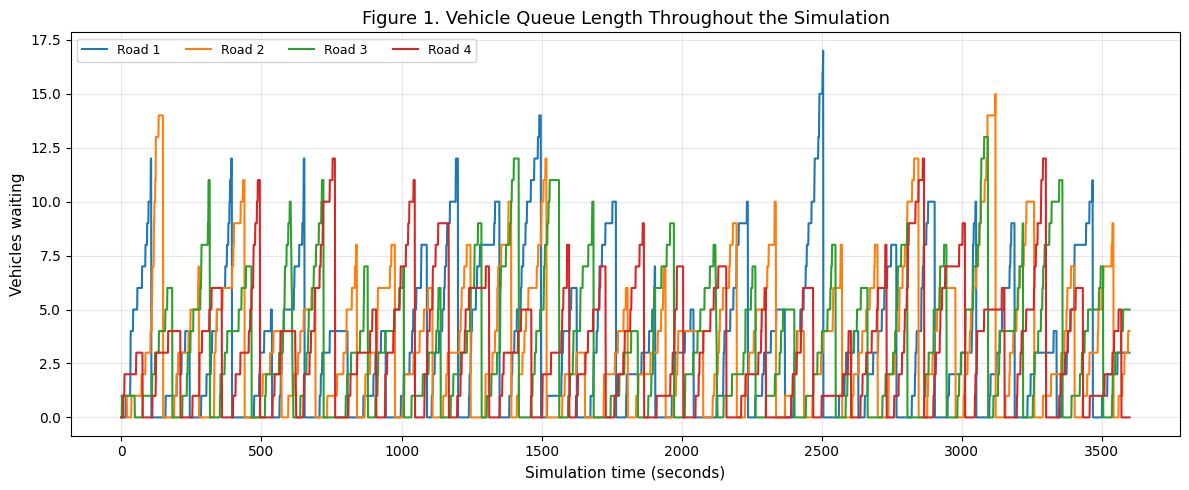

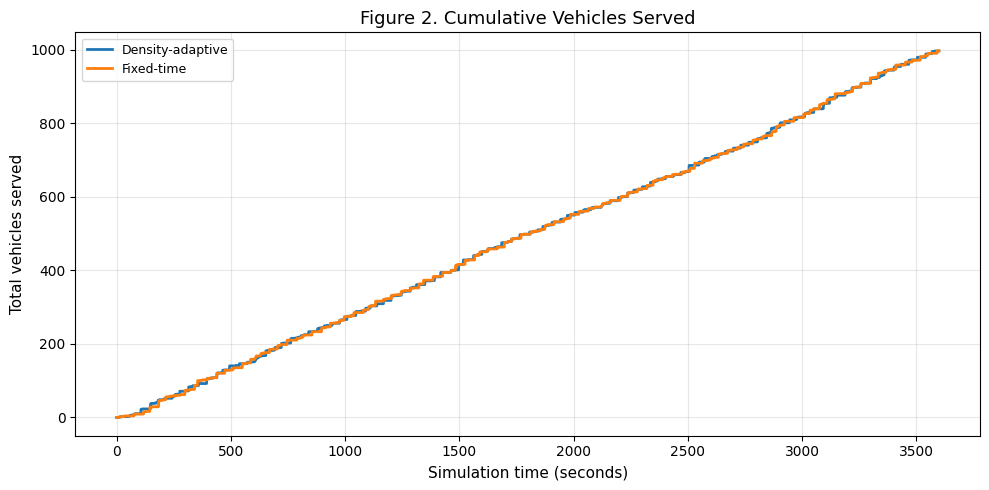

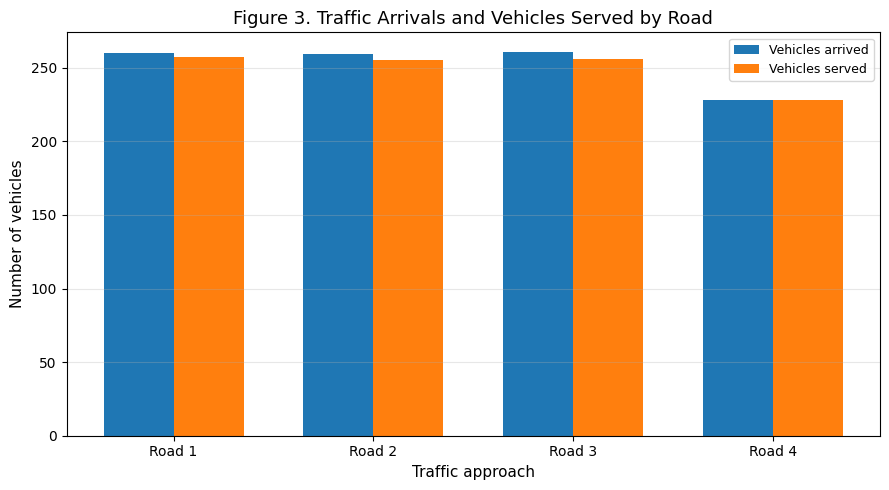

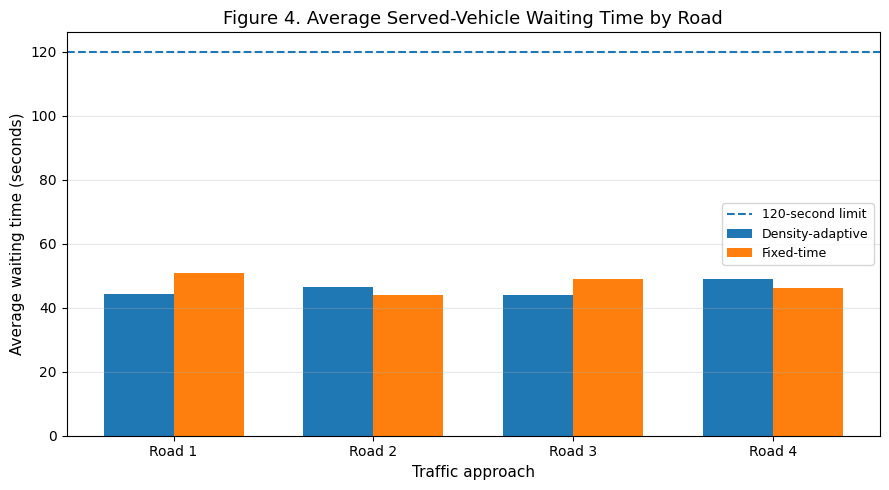

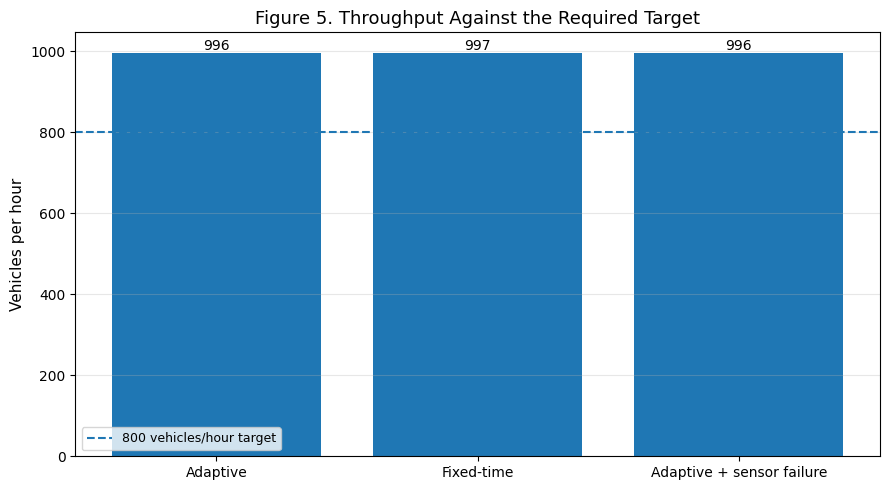

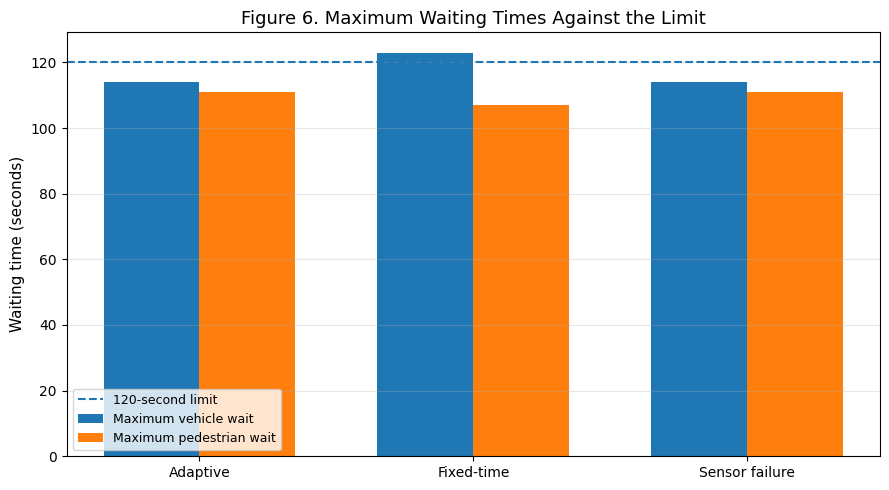

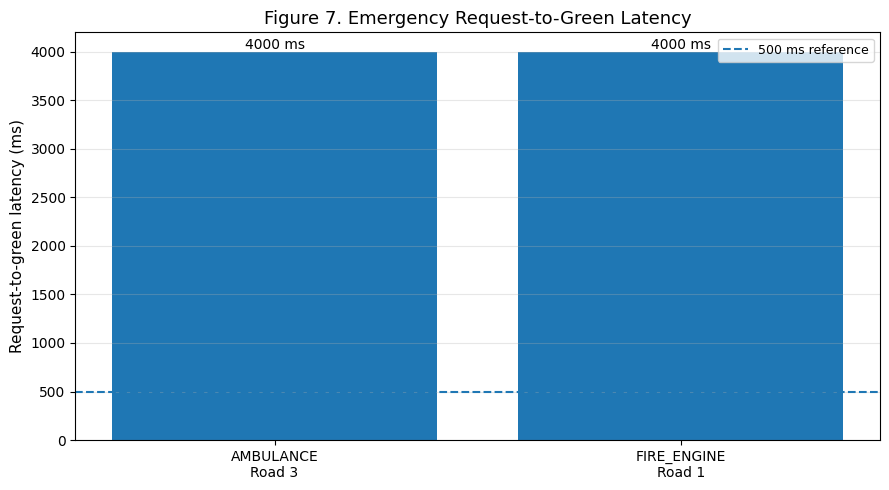

## Final verification summary

,Category,Count
0,Functional checks passed,8
1,Functional checks failed,0
2,Not verified / assumption-based,4



Note: CPU, RAM and ROM are intentionally not marked PASS here. Verify them using the target firmware IDE and hardware.
Emergency command latency is assumed; request-to-green latency is a separate measurement.
Simulation and dashboard generation completed.


In [ ]:

# ================================================================
# SMART TRAFFIC-JUNCTION CONTROLLER
# PROFESSIONAL SIMULATION DASHBOARD FOR CEP
# Google Colab: tables, charts, and functional verification
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
from collections import deque
from IPython.display import display, Markdown

# -------------------- 1. CONFIGURATION --------------------

ROADS = 4
SIM_TIME = 3600
ARRIVAL_RATES = [250, 250, 250, 250]

MIN_GREEN = 15
MAX_GREEN = 90
YELLOW = 3
ALL_RED = 2
PED_CROSSING_TIME = 7

DENSITY_UPDATE = 2
WAIT_LIMIT = 120
WAIT_PRIORITY = 100
THROUGHPUT_TARGET = 800
VEHICLES_PER_GREEN_SECOND = 1.2

UART_BAUD = 9600
UART_REPORT_INTERVAL = 60
UART_BYTES_PER_REPORT = 40
PEDESTRIAN_REQUEST_INTERVAL = 180

EMERGENCY_EVENTS = [
    (600, 2, "AMBULANCE"),
    (2100, 0, "FIRE_ENGINE")
]

ASSUMED_COMMAND_LATENCY_MS = 100
RANDOM_SEED = 42


# -------------------- 2. SIMULATION FUNCTION --------------------

def run_simulation(policy="adaptive", sensor_failure_road=None,
                   seed=RANDOM_SEED):

    random.seed(seed)
    np.random.seed(seed)

    queues = [deque() for _ in range(ROADS)]
    arrival_count = [0] * ROADS
    served_count = [0] * ROADS

    vehicle_waits = [[] for _ in range(ROADS)]
    green_history = [[] for _ in range(ROADS)]

    ped_requests = [deque() for _ in range(ROADS)]
    ped_waits = [[] for _ in range(ROADS)]
    ped_served = [0] * ROADS

    density = [0] * ROADS
    sensor_status = [True] * ROADS

    if sensor_failure_road is not None:
        sensor_status[sensor_failure_road] = False

    lamps = {
        r: {"RED": True, "YELLOW": False, "GREEN": False}
        for r in range(ROADS)
    }

    phase = "GREEN"
    current_road = 0
    phase_elapsed = 0
    green_duration = MIN_GREEN
    service_credit = 0.0

    emergency_index = 0
    active_emergency = None
    emergency_green_remaining = 0

    emergency_log = []
    emergency_green_latencies = []
    emergency_command_latencies = []

    pedestrian_total_requests = 0
    density_update_count = 0
    uart_reports = 0

    next_ped_request = [
        random.randint(30, PEDESTRIAN_REQUEST_INTERVAL)
        for _ in range(ROADS)
    ]

    queue_history = np.zeros((SIM_TIME, ROADS), dtype=int)
    cumulative_served_history = np.zeros(SIM_TIME, dtype=int)
    phase_history = []
    density_history = np.zeros((SIM_TIME, ROADS), dtype=int)

    def update_lamps(green_road=None, yellow_road=None):
        for r in range(ROADS):
            if r == green_road:
                lamps[r] = {
                    "RED": False, "YELLOW": False, "GREEN": True
                }
            elif r == yellow_road:
                lamps[r] = {
                    "RED": False, "YELLOW": True, "GREEN": False
                }
            else:
                lamps[r] = {
                    "RED": True, "YELLOW": False, "GREEN": False
                }

    def read_density(road):
        if sensor_status[road]:
            return min(255, len(queues[road]))
        return density[road]

    def choose_next_road(now):
        scores = []

        for r in range(ROADS):
            oldest_wait = now - queues[r][0] if queues[r] else 0
            score = oldest_wait * 2.0 + len(queues[r]) * 0.25
            scores.append(score)

        return int(np.argmax(scores))

    def calculate_green_duration(road):
        if policy == "fixed":
            return 30

        demand = max(len(queues[road]), density[road])
        duration = MIN_GREEN + int(demand * 1.5)

        return int(np.clip(duration, MIN_GREEN, MAX_GREEN))

    def serve_vehicle(road, now):
        if not queues[road]:
            return False

        arrival_time = queues[road].popleft()
        vehicle_waits[road].append(now - arrival_time)
        served_count[road] += 1
        return True

    def serve_pedestrian(road, now):
        if not ped_requests[road]:
            return False

        request_time = ped_requests[road].popleft()
        ped_waits[road].append(now - request_time)
        ped_served[road] += 1
        return True

    update_lamps(green_road=current_road)

    # -------------------- 3. TIME-STEP LOOP --------------------

    for t in range(SIM_TIME):

        # Vehicle arrivals
        for road in range(ROADS):
            new_arrivals = np.random.poisson(
                ARRIVAL_RATES[road] / 3600.0
            )

            for _ in range(new_arrivals):
                queues[road].append(t)
                arrival_count[road] += 1

        # Density sampling
        if t % DENSITY_UPDATE == 0:
            for road in range(ROADS):
                density[road] = read_density(road)
            density_update_count += 1

        for road in range(ROADS):
            density_history[t, road] = density[road]

        # Pedestrian requests
        for road in range(ROADS):
            if t >= next_ped_request[road]:
                ped_requests[road].append(t)
                pedestrian_total_requests += 1

                next_ped_request[road] = t + random.randint(
                    PEDESTRIAN_REQUEST_INTERVAL // 2,
                    PEDESTRIAN_REQUEST_INTERVAL * 2
                )

        # Emergency detection
        if (
            emergency_index < len(EMERGENCY_EVENTS)
            and t >= EMERGENCY_EVENTS[emergency_index][0]
            and active_emergency is None
        ):
            event_time, emergency_road, emergency_type = (
                EMERGENCY_EVENTS[emergency_index]
            )

            active_emergency = {
                "road": emergency_road,
                "type": emergency_type,
                "request_time": event_time,
                "green_time": None
            }

            emergency_command_latencies.append(
                ASSUMED_COMMAND_LATENCY_MS
            )

            emergency_log.append({
                "type": emergency_type,
                "road": emergency_road + 1,
                "request_time": event_time,
                "command_latency_ms": ASSUMED_COMMAND_LATENCY_MS,
                "green_time": None,
                "request_to_green_ms": None
            })

            emergency_index += 1
            phase = "EMERGENCY_YELLOW"
            phase_elapsed = 0
            update_lamps(yellow_road=current_road)

        # Emergency state machine
        if active_emergency is not None:

            if phase == "EMERGENCY_YELLOW":
                phase_elapsed += 1

                if phase_elapsed >= YELLOW:
                    phase = "EMERGENCY_ALL_RED"
                    phase_elapsed = 0
                    update_lamps()

            elif phase == "EMERGENCY_ALL_RED":
                phase_elapsed += 1

                if phase_elapsed >= ALL_RED:
                    phase = "EMERGENCY_GREEN"
                    phase_elapsed = 0

                    current_road = active_emergency["road"]
                    active_emergency["green_time"] = t

                    latency_ms = (
                        t - active_emergency["request_time"]
                    ) * 1000

                    emergency_green_latencies.append(latency_ms)

                    for event in reversed(emergency_log):
                        if event["green_time"] is None:
                            event["green_time"] = t
                            event["request_to_green_ms"] = latency_ms
                            break

                    emergency_green_remaining = MIN_GREEN
                    service_credit = 0.0
                    update_lamps(green_road=current_road)

            elif phase == "EMERGENCY_GREEN":
                road = active_emergency["road"]

                service_credit += VEHICLES_PER_GREEN_SECOND

                while service_credit >= 1.0:
                    if not serve_vehicle(road, t):
                        break
                    service_credit -= 1.0

                emergency_green_remaining -= 1
                phase_elapsed += 1

                if emergency_green_remaining <= 0:
                    active_emergency = None
                    phase = "ALL_RED"
                    phase_elapsed = 0
                    service_credit = 0.0
                    update_lamps()

            if phase.startswith("EMERGENCY"):
                phase_history.append(phase)
                queue_history[t, :] = [len(q) for q in queues]
                cumulative_served_history[t] = sum(served_count)

                # Still count periodic reporting during emergency phases.
                if (t + 1) % UART_REPORT_INTERVAL == 0:
                    uart_reports += 1
                continue

        # Normal GREEN
        if phase == "GREEN":

            if phase_elapsed == 0:
                green_duration = calculate_green_duration(current_road)
                green_history[current_road].append(green_duration)

            service_credit += VEHICLES_PER_GREEN_SECOND

            while service_credit >= 1.0:
                if not serve_vehicle(current_road, t):
                    break
                service_credit -= 1.0

            phase_elapsed += 1

            oldest_ped_wait = (
                t - ped_requests[current_road][0]
                if ped_requests[current_road] else 0
            )

            oldest_other_wait = 0

            for road in range(ROADS):
                if road != current_road and queues[road]:
                    oldest_other_wait = max(
                        oldest_other_wait,
                        t - queues[road][0]
                    )

            vehicle_priority = (
                phase_elapsed >= MIN_GREEN
                and oldest_other_wait >= WAIT_PRIORITY
            )

            pedestrian_priority = (
                bool(ped_requests[current_road])
                and oldest_ped_wait >= 75
            )

            if (
                phase_elapsed >= green_duration
                or vehicle_priority
                or pedestrian_priority
            ):
                phase = "YELLOW"
                phase_elapsed = 0
                update_lamps(yellow_road=current_road)

        # Normal YELLOW
        elif phase == "YELLOW":
            phase_elapsed += 1

            if phase_elapsed >= YELLOW:
                phase = "ALL_RED"
                phase_elapsed = 0
                update_lamps()

        # Normal ALL-RED
        elif phase == "ALL_RED":
            phase_elapsed += 1

            if phase_elapsed >= ALL_RED:
                waiting_pedestrians = [
                    r for r in range(ROADS) if ped_requests[r]
                ]

                if waiting_pedestrians:
                    ped_road = max(
                        waiting_pedestrians,
                        key=lambda r: t - ped_requests[r][0]
                    )

                    serve_pedestrian(ped_road, t)
                    phase = "PEDESTRIAN"
                    phase_elapsed = 0
                    update_lamps()
                else:
                    current_road = choose_next_road(t)
                    phase = "GREEN"
                    phase_elapsed = 0
                    update_lamps(green_road=current_road)

        # Pedestrian crossing phase
        elif phase == "PEDESTRIAN":
            phase_elapsed += 1

            if phase_elapsed >= PED_CROSSING_TIME:
                current_road = choose_next_road(t)
                phase = "GREEN"
                phase_elapsed = 0
                update_lamps(green_road=current_road)

        # Record histories and serial reporting
        phase_history.append(phase)
        queue_history[t, :] = [len(q) for q in queues]
        cumulative_served_history[t] = sum(served_count)

        if (t + 1) % UART_REPORT_INTERVAL == 0:
            uart_reports += 1

    # -------------------- 4. METRICS --------------------

    total_arrived = sum(arrival_count)
    total_served = sum(served_count)
    total_remaining = sum(len(q) for q in queues)

    throughput = total_served * 3600 / SIM_TIME

    all_vehicle_waits = [
        w for road_waits in vehicle_waits for w in road_waits
    ]
    all_ped_waits = [
        w for road_waits in ped_waits for w in road_waits
    ]

    max_vehicle_wait = max(
        all_vehicle_waits
        + [SIM_TIME - q[0] for q in queues if q]
        + [0]
    )

    max_ped_wait = max(
        all_ped_waits
        + [SIM_TIME - q[0] for q in ped_requests if q]
        + [0]
    )

    avg_vehicle_wait = (
        float(np.mean(all_vehicle_waits))
        if all_vehicle_waits else 0.0
    )

    uart_utilization = (
        uart_reports * UART_BYTES_PER_REPORT * 10
        / (UART_BAUD * SIM_TIME)
    ) * 100

    return {
        "policy": policy,
        "sensor_failure_road": sensor_failure_road,
        "arrival_count": arrival_count,
        "served_count": served_count,
        "vehicle_waits": vehicle_waits,
        "ped_waits": ped_waits,
        "ped_served": ped_served,
        "green_history": green_history,
        "total_arrived": total_arrived,
        "total_served": total_served,
        "total_remaining": total_remaining,
        "throughput": throughput,
        "avg_vehicle_wait": avg_vehicle_wait,
        "maximum_vehicle_wait": max_vehicle_wait,
        "maximum_pedestrian_wait": max_ped_wait,
        "pedestrian_total_requests": pedestrian_total_requests,
        "uart_reports": uart_reports,
        "uart_utilization": uart_utilization,
        "density_update_count": density_update_count,
        "emergency_log": emergency_log,
        "emergency_command_latencies": emergency_command_latencies,
        "emergency_green_latencies": emergency_green_latencies,
        "queue_history": queue_history,
        "cumulative_served_history": cumulative_served_history,
        "phase_history": phase_history,
        "density_history": density_history,
        "sensor_status": sensor_status
    }


# -------------------- 5. RUN SCENARIOS --------------------

display(Markdown("# Smart Traffic-Junction Controller"))
display(Markdown(
    "Simulation duration: **1 hour** | Approaches: **4** | "
    "Throughput target: **800 vehicles/hour**"
))

print("Running baseline adaptive controller...")
adaptive = run_simulation(policy="adaptive")

print("Running fixed-time comparison...")
fixed = run_simulation(policy="fixed")

print("Running sensor-failure scenario...")
sensor_test = run_simulation(
    policy="adaptive",
    sensor_failure_road=2
)


# -------------------- 6. SUMMARY TABLES --------------------

def average_per_road(result, key):
    output = []
    for values in result[key]:
        output.append(float(np.mean(values)) if values else 0.0)
    return output


summary_df = pd.DataFrame([
    {
        "Scenario": "Adaptive - Normal",
        "Arrived": adaptive["total_arrived"],
        "Served": adaptive["total_served"],
        "Throughput (veh/h)": round(adaptive["throughput"], 2),
        "Avg vehicle wait (s)": round(adaptive["avg_vehicle_wait"], 2),
        "Max vehicle wait (s)": adaptive["maximum_vehicle_wait"],
        "Max pedestrian wait (s)": adaptive["maximum_pedestrian_wait"],
        "Vehicles remaining": adaptive["total_remaining"]
    },
    {
        "Scenario": "Fixed-time",
        "Arrived": fixed["total_arrived"],
        "Served": fixed["total_served"],
        "Throughput (veh/h)": round(fixed["throughput"], 2),
        "Avg vehicle wait (s)": round(fixed["avg_vehicle_wait"], 2),
        "Max vehicle wait (s)": fixed["maximum_vehicle_wait"],
        "Max pedestrian wait (s)": fixed["maximum_pedestrian_wait"],
        "Vehicles remaining": fixed["total_remaining"]
    },
    {
        "Scenario": "Adaptive - Sensor failure",
        "Arrived": sensor_test["total_arrived"],
        "Served": sensor_test["total_served"],
        "Throughput (veh/h)": round(sensor_test["throughput"], 2),
        "Avg vehicle wait (s)": round(sensor_test["avg_vehicle_wait"], 2),
        "Max vehicle wait (s)": sensor_test["maximum_vehicle_wait"],
        "Max pedestrian wait (s)": sensor_test["maximum_pedestrian_wait"],
        "Vehicles remaining": sensor_test["total_remaining"]
    }
])

display(Markdown("## Table 1. Overall performance comparison"))
display(summary_df)


road_rows = []

for road in range(ROADS):
    waits = adaptive["vehicle_waits"][road]
    ped_waits_road = adaptive["ped_waits"][road]

    road_rows.append({
        "Road": f"Road {road + 1}",
        "Arrivals": adaptive["arrival_count"][road],
        "Vehicles served": adaptive["served_count"][road],
        "Avg vehicle wait (s)": round(
            float(np.mean(waits)) if waits else 0, 2
        ),
        "Max served wait (s)": max(waits) if waits else 0,
        "Pedestrians served": adaptive["ped_served"][road],
        "Avg green (s)": round(
            float(np.mean(adaptive["green_history"][road]))
            if adaptive["green_history"][road] else 0, 2
        ),
        "Sensor status": (
            "Working" if adaptive["sensor_status"][road] else "Failed"
        )
    })

road_df = pd.DataFrame(road_rows)

display(Markdown("## Table 2. Road-wise performance"))
display(road_df)


# -------------------- 7. REQUIREMENT VERIFICATION TABLE --------------------

checks = [
    {
        "Requirement": "Throughput >= 800 vehicles/hour",
        "Measured value": f"{adaptive['throughput']:.2f} vehicles/hour",
        "Acceptance criterion": ">= 800 vehicles/hour",
        "Status": "PASS" if adaptive["throughput"] >= THROUGHPUT_TARGET else "FAIL"
    },
    {
        "Requirement": "Maximum vehicle wait",
        "Measured value": f"{adaptive['maximum_vehicle_wait']} seconds",
        "Acceptance criterion": "<= 120 seconds",
        "Status": "PASS" if adaptive["maximum_vehicle_wait"] <= WAIT_LIMIT else "FAIL"
    },
    {
        "Requirement": "Maximum pedestrian wait",
        "Measured value": f"{adaptive['maximum_pedestrian_wait']} seconds",
        "Acceptance criterion": "<= 120 seconds",
        "Status": "PASS" if adaptive["maximum_pedestrian_wait"] <= WAIT_LIMIT else "FAIL"
    },
    {
        "Requirement": "Density update frequency",
        "Measured value": f"{adaptive['density_update_count']} updates",
        "Acceptance criterion": "1800 updates per hour",
        "Status": "PASS" if adaptive["density_update_count"] == SIM_TIME // DENSITY_UPDATE else "FAIL"
    },
    {
        "Requirement": "Serial reporting",
        "Measured value": f"{adaptive['uart_reports']} reports",
        "Acceptance criterion": "60 reports per hour",
        "Status": "PASS" if adaptive["uart_reports"] == SIM_TIME // UART_REPORT_INTERVAL else "FAIL"
    },
    {
        "Requirement": "Both emergency events reach green",
        "Measured value": f"{sum(e['green_time'] is not None for e in adaptive['emergency_log'])} of {len(EMERGENCY_EVENTS)} events",
        "Acceptance criterion": "Both events completed",
        "Status": "PASS" if len(adaptive["emergency_log"]) == len(EMERGENCY_EVENTS) and all(e["green_time"] is not None for e in adaptive["emergency_log"]) else "FAIL"
    },
    {
        "Requirement": "Assumed emergency command latency",
        "Measured value": f"{ASSUMED_COMMAND_LATENCY_MS} ms (assumed)",
        "Acceptance criterion": "<= 500 ms",
        "Status": "ASSUMPTION - NOT HARDWARE VERIFIED"
    },
    {
        "Requirement": "Sensor-failure operation",
        "Measured value": f"{sensor_test['total_served']} vehicles served",
        "Acceptance criterion": "Controller continues operating",
        "Status": "PASS" if sensor_test["total_served"] > 0 else "FAIL"
    },
    {
        "Requirement": "Sensor-failure throughput",
        "Measured value": f"{sensor_test['throughput']:.2f} vehicles/hour",
        "Acceptance criterion": ">= 800 vehicles/hour",
        "Status": "PASS" if sensor_test["throughput"] >= THROUGHPUT_TARGET else "FAIL"
    },
    {
        "Requirement": "Firmware RAM <= 256 bytes",
        "Measured value": "Requires target IDE",
        "Acceptance criterion": "<= 256 bytes",
        "Status": "NOT VERIFIED"
    },
    {
        "Requirement": "Firmware ROM <= 8 KB",
        "Measured value": "Requires target IDE",
        "Acceptance criterion": "<= 8192 bytes",
        "Status": "NOT VERIFIED"
    },
    {
        "Requirement": "Target CPU utilisation <= 30%",
        "Measured value": "Requires target hardware",
        "Acceptance criterion": "<= 30%",
        "Status": "NOT VERIFIED"
    }
]

verification_df = pd.DataFrame(checks)

display(Markdown("## Table 3. Functional requirement verification"))
display(verification_df)


# -------------------- 8. EMERGENCY TABLE --------------------

emergency_rows = []

for event in adaptive["emergency_log"]:
    emergency_rows.append({
        "Emergency type": event["type"],
        "Road": event["road"],
        "Request time (s)": event["request_time"],
        "Command latency (ms)": event["command_latency_ms"],
        "Green time (s)": (
            event["green_time"]
            if event["green_time"] is not None else "Not completed"
        ),
        "Request-to-green (ms)": (
            event["request_to_green_ms"]
            if event["request_to_green_ms"] is not None
            else "Not completed"
        )
    })

display(Markdown("## Table 4. Emergency-response analysis"))
display(pd.DataFrame(emergency_rows))


# -------------------- 9. PLOTS --------------------

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "legend.fontsize": 9
})

time_axis = np.arange(SIM_TIME)

# Plot 1: queue lengths
fig, ax = plt.subplots(figsize=(12, 5))

for road in range(ROADS):
    ax.plot(
        time_axis,
        adaptive["queue_history"][:, road],
        label=f"Road {road + 1}",
        linewidth=1.5
    )

ax.set_title("Figure 1. Vehicle Queue Length Throughout the Simulation")
ax.set_xlabel("Simulation time (seconds)")
ax.set_ylabel("Vehicles waiting")
ax.grid(True, alpha=0.3)
ax.legend(ncol=4)
plt.tight_layout()
plt.show()


# Plot 2: cumulative vehicles served
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    time_axis,
    adaptive["cumulative_served_history"],
    label="Density-adaptive",
    linewidth=2
)

ax.plot(
    time_axis,
    fixed["cumulative_served_history"],
    label="Fixed-time",
    linewidth=2
)

ax.set_title("Figure 2. Cumulative Vehicles Served")
ax.set_xlabel("Simulation time (seconds)")
ax.set_ylabel("Total vehicles served")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


# Plot 3: arrivals vs served by road
x = np.arange(ROADS)
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    x - width / 2,
    adaptive["arrival_count"],
    width,
    label="Vehicles arrived"
)

ax.bar(
    x + width / 2,
    adaptive["served_count"],
    width,
    label="Vehicles served"
)

ax.set_title("Figure 3. Traffic Arrivals and Vehicles Served by Road")
ax.set_xlabel("Traffic approach")
ax.set_ylabel("Number of vehicles")
ax.set_xticks(x)
ax.set_xticklabels([f"Road {r + 1}" for r in range(ROADS)])
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


# Plot 4: average waiting time by road
adaptive_avg = average_per_road(adaptive, "vehicle_waits")
fixed_avg = average_per_road(fixed, "vehicle_waits")

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(x - width / 2, adaptive_avg, width, label="Density-adaptive")
ax.bar(x + width / 2, fixed_avg, width, label="Fixed-time")
ax.axhline(
    WAIT_LIMIT,
    linestyle="--",
    linewidth=1.5,
    label="120-second limit"
)

ax.set_title("Figure 4. Average Served-Vehicle Waiting Time by Road")
ax.set_xlabel("Traffic approach")
ax.set_ylabel("Average waiting time (seconds)")
ax.set_xticks(x)
ax.set_xticklabels([f"Road {r + 1}" for r in range(ROADS)])
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


# Plot 5: throughput comparison
fig, ax = plt.subplots(figsize=(9, 5))

scenario_names = [
    "Adaptive",
    "Fixed-time",
    "Adaptive + sensor failure"
]

throughputs = [
    adaptive["throughput"],
    fixed["throughput"],
    sensor_test["throughput"]
]

bars = ax.bar(scenario_names, throughputs)

ax.axhline(
    THROUGHPUT_TARGET,
    linestyle="--",
    linewidth=1.5,
    label="800 vehicles/hour target"
)

ax.bar_label(bars, fmt="%.0f")
ax.set_title("Figure 5. Throughput Against the Required Target")
ax.set_ylabel("Vehicles per hour")
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


# Plot 6: maximum vehicle and pedestrian waits
fig, ax = plt.subplots(figsize=(9, 5))

scenario_names = ["Adaptive", "Fixed-time", "Sensor failure"]

vehicle_max = [
    adaptive["maximum_vehicle_wait"],
    fixed["maximum_vehicle_wait"],
    sensor_test["maximum_vehicle_wait"]
]

pedestrian_max = [
    adaptive["maximum_pedestrian_wait"],
    fixed["maximum_pedestrian_wait"],
    sensor_test["maximum_pedestrian_wait"]
]

x3 = np.arange(len(scenario_names))
width3 = 0.35

ax.bar(x3 - width3 / 2, vehicle_max, width3, label="Maximum vehicle wait")
ax.bar(x3 + width3 / 2, pedestrian_max, width3, label="Maximum pedestrian wait")

ax.axhline(
    WAIT_LIMIT,
    linestyle="--",
    linewidth=1.5,
    label="120-second limit"
)

ax.set_title("Figure 6. Maximum Waiting Times Against the Limit")
ax.set_ylabel("Waiting time (seconds)")
ax.set_xticks(x3)
ax.set_xticklabels(scenario_names)
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


# Plot 7: emergency request-to-green latency
fig, ax = plt.subplots(figsize=(9, 5))

if adaptive["emergency_log"]:
    event_labels = [
        f"{e['type']}\nRoad {e['road']}"
        for e in adaptive["emergency_log"]
    ]

    latencies = [
        e["request_to_green_ms"]
        if e["request_to_green_ms"] is not None else np.nan
        for e in adaptive["emergency_log"]
    ]

    bars = ax.bar(event_labels, latencies)
    ax.axhline(
        500,
        linestyle="--",
        linewidth=1.5,
        label="500 ms reference"
    )

    ax.bar_label(bars, fmt="%.0f ms")
    ax.set_ylabel("Request-to-green latency (ms)")
    ax.set_title("Figure 7. Emergency Request-to-Green Latency")
    ax.legend()
    ax.grid(axis="y", alpha=0.3)
else:
    ax.text(0.5, 0.5, "No emergency events recorded", ha="center")

plt.tight_layout()
plt.show()


# -------------------- 10. FINAL DASHBOARD --------------------

passed = sum(row["Status"] == "PASS" for row in checks)
failed = sum(row["Status"] == "FAIL" for row in checks)
not_verified = sum(
    row["Status"] in [
        "NOT VERIFIED",
        "ASSUMPTION - NOT HARDWARE VERIFIED"
    ]
    for row in checks
)

display(Markdown("## Final verification summary"))

display(pd.DataFrame([
    {"Category": "Functional checks passed", "Count": passed},
    {"Category": "Functional checks failed", "Count": failed},
    {"Category": "Not verified / assumption-based", "Count": not_verified}
]))

print(
    "\nNote: CPU, RAM and ROM are intentionally not marked PASS here. "
    "Verify them using the target firmware IDE and hardware."
)
print(
    "Emergency command latency is assumed; request-to-green latency "
    "is a separate measurement."
)
print("Simulation and dashboard generation completed.")
